| <h1> **Portuguese Bank Marketing – Customer Term Deposit Subscription Prediction**</h1> |
| :----|

**Project Code:** PRCP-1000

**Project Type:** Data Analysis and Machine Learning – Binary Classification

## Domain

**Finance and Banking**

This project focuses on analyzing customer data from a Portuguese banking institution to understand customer responses to direct phone call marketing campaigns promoting term deposits.

## Problem Statement

A Portuguese banking institution conducted direct phone call marketing campaigns to promote term deposits among its existing customers between May 2008 and November 2010.

The bank needs to understand customer behavior and identify customers who are more likely to subscribe to a term deposit.

The main problem is to analyze historical marketing campaign data, develop a predictive model to identify potential customers, and provide useful marketing suggestions to improve subscription rates.

## Business Objective

The main business objective is to help the bank's marketing team improve the effectiveness of direct marketing campaigns.

The objectives are:

1. Analyze customer demographic, financial, and campaign-related information.
2. Identify the factors that influence term deposit subscriptions.
3. Develop a machine learning model to predict whether a customer will subscribe to a term deposit.
4. Identify potential customers for targeted marketing campaigns.
5. Recommend strategies to improve customer response and subscription rates.
6. Compare multiple machine learning models and select the best-performing model for production.

## Dataset Description

The dataset contains information about direct phone call marketing campaigns conducted by a Portuguese banking institution between May 2008 and November 2010.

The campaigns aimed to promote term deposits among existing bank customers.

**Dataset File:** `bank-additional-full.csv`

**Dataset Location:** `Data/bank-additional/bank-additional-full.csv`

**Domain:** Finance and Banking

**Input Variables:** 20 independent variables

**Target Variable:** `y`

**Target Variable Description:**
- `yes` – Customer subscribed to a term deposit.
- `no` – Customer did not subscribe to a term deposit.

The dataset includes the following types of information:

1. Customer demographic details.
2. Customer financial and loan information.
3. Marketing campaign contact details.
4. Previous campaign information.
5. Social and economic indicators.

The target variable `y` is a binary categorical variable.

## Project Goals

The main goals of this project are:

1. Perform exploratory data analysis (EDA) to understand the dataset.
2. Identify missing values, duplicate records, and data quality issues.
3. Analyze customer characteristics and marketing campaign performance.
4. Identify important features that influence term deposit subscriptions.
5. Perform data preprocessing and feature engineering.
6. Build multiple machine learning classification models.
7. Evaluate models using appropriate performance metrics.
8. Compare model performance and select the best model.
9. Provide data-driven marketing recommendations to improve subscription rates.
10. Identify project challenges and explain the techniques used to solve them.

## Project Workflow

The project will be completed through the following steps:

1. **Project Understanding** – Understand the business problem and project requirements.
2. **Data Collection** – Load the provided dataset.
3. **Data Understanding** – Examine dataset structure, features, and target variable.
4. **Data Validation** – Check missing values, duplicates, incorrect values, and data types.
5. **Data Cleaning** – Handle data quality issues.
6. **Exploratory Data Analysis (EDA)** – Perform univariate, bivariate, and multivariate analysis.
7. **Feature Engineering** – Create meaningful features where required.
8. **Feature Selection** – Identify relevant features for model development.
9. **Data Preprocessing** – Encode categorical variables and scale numerical variables where required.
10. **Train-Test Split** – Divide the dataset into training and testing sets.
11. **Class Imbalance Handling** – Apply suitable techniques if required.
12. **Model Building** – Train multiple classification algorithms.
13. **Model Evaluation** – Evaluate models using suitable performance metrics.
14. **Model Comparison** – Compare model performance.
15. **Hyperparameter Tuning** – Optimize the selected models.
16. **Final Model Selection** – Select the most suitable model for production.
17. **Business Recommendations** – Suggest marketing strategies based on the analysis and model results.
18. **Challenges and Solutions** – Document challenges and techniques used to address them.
19. **Final Conclusion** – Summarize the project findings and outcomes.

| <h1> **Imports the Necessary Libraries**:</h1> |
| :--- |

In [61]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
import warnings
warnings.filterwarnings('ignore')


| <h1> **Data Loading Step**:</h1> |
| :--- |

In [62]:
df = pd.read_csv(
    "../../jupyter/bank-additional-full.csv",
    sep=";"
)


| <h1> **Data Understanding**:</h1> |
| :--- |

In [63]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [64]:
df.tail()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [65]:
df.shape

(41188, 21)

In [66]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='str')

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [68]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [69]:
df.describe(include='object')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548



## Data Understanding

- The dataset contains 41,188 records and 21 columns.
- It contains 20 independent features and 1 target variable.
- The dataset includes numerical and categorical features.
- All columns contain 41,188 non-null values.
- No missing values were identified.
- Numerical features include customer age, call duration, campaign contacts and economic indicators.
- Categorical features include job, marital status, education and contact details.
- Admin is the most common job category.
- Married is the most common marital status.
- University degree is the most common education level.
- Cellular is the most common contact method.
- May is the most frequent contact month.
- Most customers did not subscribe to a term deposit.
- The target variable is `y`, containing Yes and No classes.

## Conclusion

The dataset is suitable for binary classification to predict whether a customer will subscribe to a bank term deposit.


| <h1> **Data Validation and Data Cleaning**:</h1> |
| :--- |

In [70]:
df.isnull().sum().sum()

np.int64(0)

In [71]:
df.duplicated().sum()

np.int64(12)

In [72]:
df[df.duplicated()]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
20216,55,services,married,high.school,unknown,no,no,cellular,aug,mon,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
20534,41,technician,married,professional.course,no,yes,no,cellular,aug,tue,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no
25217,39,admin.,married,university.degree,no,no,no,cellular,nov,tue,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.153,5195.8,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no


In [73]:
(df.duplicated().mean() * 100).round(2)

np.float64(0.03)

## Duplicate Records Analysis

- A total of 12 duplicate records were identified.
- Duplicate records account for approximately 0.03% of the dataset.
- Duplicate records may affect data analysis and model performance.
- Duplicate records should be removed to maintain data quality.

In [74]:
df.drop_duplicates(inplace=True)

# Check duplicates again
df.duplicated().sum()

np.int64(0)

In [75]:
df.shape

(41176, 21)

In [76]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

categorical_cols = df.select_dtypes(include=['object', 'str', 'category']).columns

print("Numerical Columns:", list(numerical_cols))
print(len(numerical_cols),"\n")

print("Categorical Columns:", list(categorical_cols))
print(len(categorical_cols),"\n")

Numerical Columns: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
10 

Categorical Columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']
11 



In [77]:
df.nunique()


age                 78
job                 12
marital              4
education            8
default              3
housing              3
loan                 3
contact              2
month               10
day_of_week          5
duration          1544
campaign            42
pdays               27
previous             8
poutcome             3
emp.var.rate        10
cons.price.idx      26
cons.conf.idx       26
euribor3m          316
nr.employed         11
y                    2
dtype: int64

In [78]:
unique_analysis = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Unique Values': df.nunique()
})

unique_analysis.sort_values(by='Unique Values')

,Data Type,Unique Values
contact,str,2
y,str,2
default,str,3
loan,str,3
poutcome,str,3
housing,str,3
marital,str,4
day_of_week,str,5
previous,int64,8
education,str,8


In [79]:
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


job:
<StringArray>
[    'housemaid',      'services',        'admin.',   'blue-collar',
    'technician',       'retired',    'management',    'unemployed',
 'self-employed',       'unknown',  'entrepreneur',       'student']
Length: 12, dtype: str

marital:
<StringArray>
['married', 'single', 'divorced', 'unknown']
Length: 4, dtype: str

education:
<StringArray>
[           'basic.4y',         'high.school',            'basic.6y',
            'basic.9y', 'professional.course',             'unknown',
   'university.degree',          'illiterate']
Length: 8, dtype: str

default:
<StringArray>
['no', 'unknown', 'yes']
Length: 3, dtype: str

housing:
<StringArray>
['no', 'yes', 'unknown']
Length: 3, dtype: str

loan:
<StringArray>
['no', 'yes', 'unknown']
Length: 3, dtype: str

contact:
<StringArray>
['telephone', 'cellular']
Length: 2, dtype: str

month:
<StringArray>
['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'mar', 'apr', 'sep']
Length: 10, dtype: str

day_of_week:
<StringArray

In [80]:
for col in numerical_cols:
    print(col, ":", (df[col] < 0).sum())

age : 0
duration : 0
campaign : 0
pdays : 0
previous : 0
emp.var.rate : 17186
cons.price.idx : 0
cons.conf.idx : 41176
euribor3m : 0
nr.employed : 0


### Negative Values Analysis

- Negative values were found in `emp.var.rate` and `cons.conf.idx`.
- These are economic indicators, so negative values are valid.
- No negative values were found in the other numerical columns.
- Therefore, negative values do not require removal.

In [81]:
print("Invalid Age:", ((df['age'] < 18) | (df['age'] > 100)).sum())

print("Invalid Campaign:", (df['campaign'] < 1).sum())

print("Invalid Previous:", (df['previous'] < 0).sum())

print("Invalid Duration:", (df['duration'] < 0).sum())

print("Invalid Pdays:", ((df['pdays'] < 0) & (df['pdays'] != 999)).sum())


Invalid Age: 5
Invalid Campaign: 0
Invalid Previous: 0
Invalid Duration: 0
Invalid Pdays: 0


In [82]:
invalid_age = df[(df['age'] < 18) | (df['age'] > 100)]

invalid_age[['age']]

,age
37140,17
37539,17
37558,17
37579,17
38274,17


- Five records have an age of 17.
- These values are retained because they may represent valid customer ages.
- No negative age values were found.

In [83]:
print(df['y'].value_counts())
print("Invalid Target:\n", (~df['y'].isin(['yes', 'no'])).sum())
df['y'].value_counts(normalize=True).mul(100).round(2)

y
no     36537
yes     4639
Name: count, dtype: int64
Invalid Target:
 0


y
no     88.73
yes    11.27
Name: proportion, dtype: float64

### Target Variable Validation

- The target column contains two unique values: Yes and No.
- No: 36,537 records (88.73%).
- Yes: 4,639 records (11.27%).
- No invalid target values were found.
- The target variable is imbalanced.

In [84]:
constant_cols = [col for col in df.columns if df[col].nunique() == 1]

print("Constant Columns:", constant_cols)
print("Number of Constant Columns:", len(constant_cols))

Constant Columns: []
Number of Constant Columns: 0


In [85]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, ":", count)

age : 468
duration : 2963
campaign : 2406
pdays : 1515
previous : 5625
emp.var.rate : 0
cons.price.idx : 0
cons.conf.idx : 446
euribor3m : 0
nr.employed : 0


In [86]:
for col in numerical_cols:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Median:", df[col].median())


age
Minimum: 17
Maximum: 98
Median: 38.0

duration
Minimum: 0
Maximum: 4918
Median: 180.0

campaign
Minimum: 1
Maximum: 56
Median: 2.0

pdays
Minimum: 0
Maximum: 999
Median: 999.0

previous
Minimum: 0
Maximum: 7
Median: 0.0

emp.var.rate
Minimum: -3.4
Maximum: 1.4
Median: 1.1

cons.price.idx
Minimum: 92.201
Maximum: 94.767
Median: 93.749

cons.conf.idx
Minimum: -50.8
Maximum: -26.9
Median: -41.8

euribor3m
Minimum: 0.634
Maximum: 5.045
Median: 4.857

nr.employed
Minimum: 4963.6
Maximum: 5228.1
Median: 5191.0


### Numerical Columns Analysis

- The `pdays` column contains 999, representing customers who were not previously contacted.
- The `previous` column has values ranging from 0 to 7.
- Economic indicators contain valid positive and negative values.
- No invalid numerical values were identified based on the observed ranges.
- Potential outliers were retained because they may represent valid observations.

| <h3> **Outlier Analysis-Numerical_columns** </h3> |
| :--- |

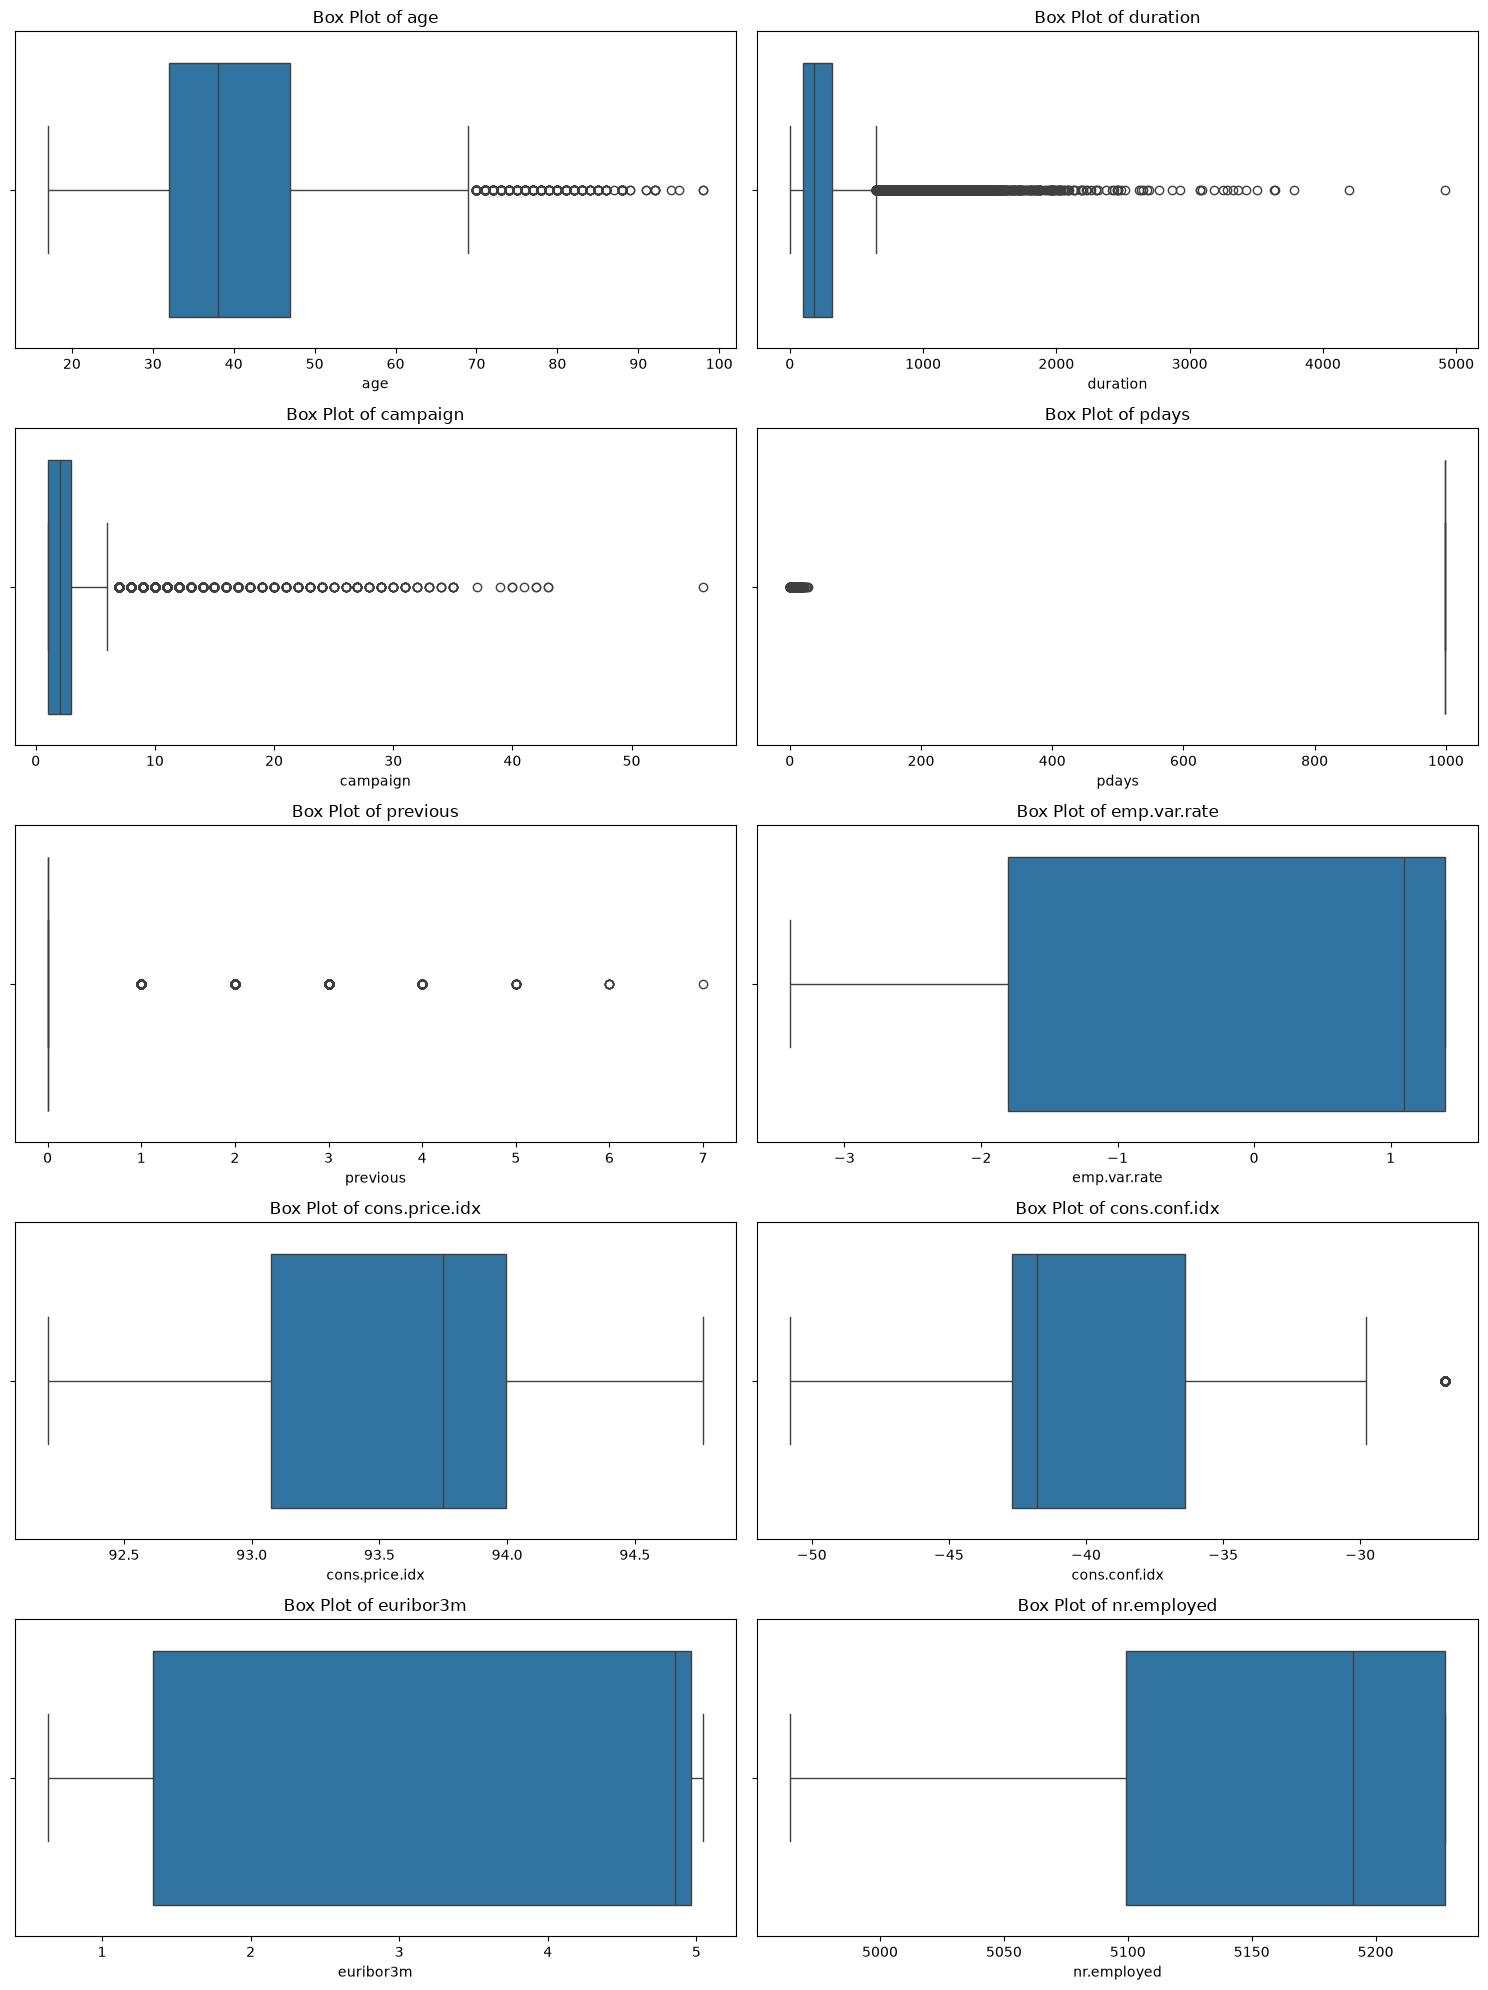

In [87]:
fig, axes = plt.subplots(5, 2, figsize=(15, 20))

for ax, col in zip(axes.flatten(), numerical_cols):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

### Outlier Analysis (Box Plots)

- **age, duration, campaign:** The distributions are right-skewed. Many customers are aged 70 and above, some calls are very long (duration), and some customers were contacted many times (campaign, up to 56). These are genuine customer behaviours, not data errors.
- **pdays and previous:** The apparent outliers come from the placeholder value `999` in `pdays` (meaning "not previously contacted") and from most customers having `0` previous contacts. They are not true outliers.
- **emp.var.rate, cons.price.idx, euribor3m, nr.employed:** No outliers were observed. The wide boxes in `euribor3m` and `nr.employed` are because their values cluster and repeat.
- **cons.conf.idx:** Only one valid extreme value was observed.

**Decision:**
- Outliers are retained, because they represent genuine customer behaviour and the "yes" class is already small (11%).
- `campaign` will be capped at the 99th percentile.
- `pdays` will be converted into a binary flag, `previously_contacted`.
- `duration` will be excluded from modeling to avoid data leakage.

| <h3> **Unknown Values Analysis** </h3> |
| :--- |

In [88]:
unknown_df = pd.DataFrame({
    'Unknown Count': (df == 'unknown').sum(),
    'Unknown Percentage (%)': ((df == 'unknown').mean() * 100).round(2)
})

unknown_df = unknown_df[unknown_df['Unknown Count'] > 0].sort_values(by='Unknown Percentage (%)', ascending=False)

print(unknown_df)


           Unknown Count  Unknown Percentage (%)
default             8596                   20.88
education           1730                    4.20
housing              990                    2.40
loan                 990                    2.40
job                  330                    0.80
marital               80                    0.19


| <h1> **Exploratory Data Analysis (EDA)** </h1> |
| :--- |

| <h2> **Univariate Analysis**</h2> |
| :--- |

| <h3> **Distribution Analysis of All Numerical Features**</h3> |
| :--- |

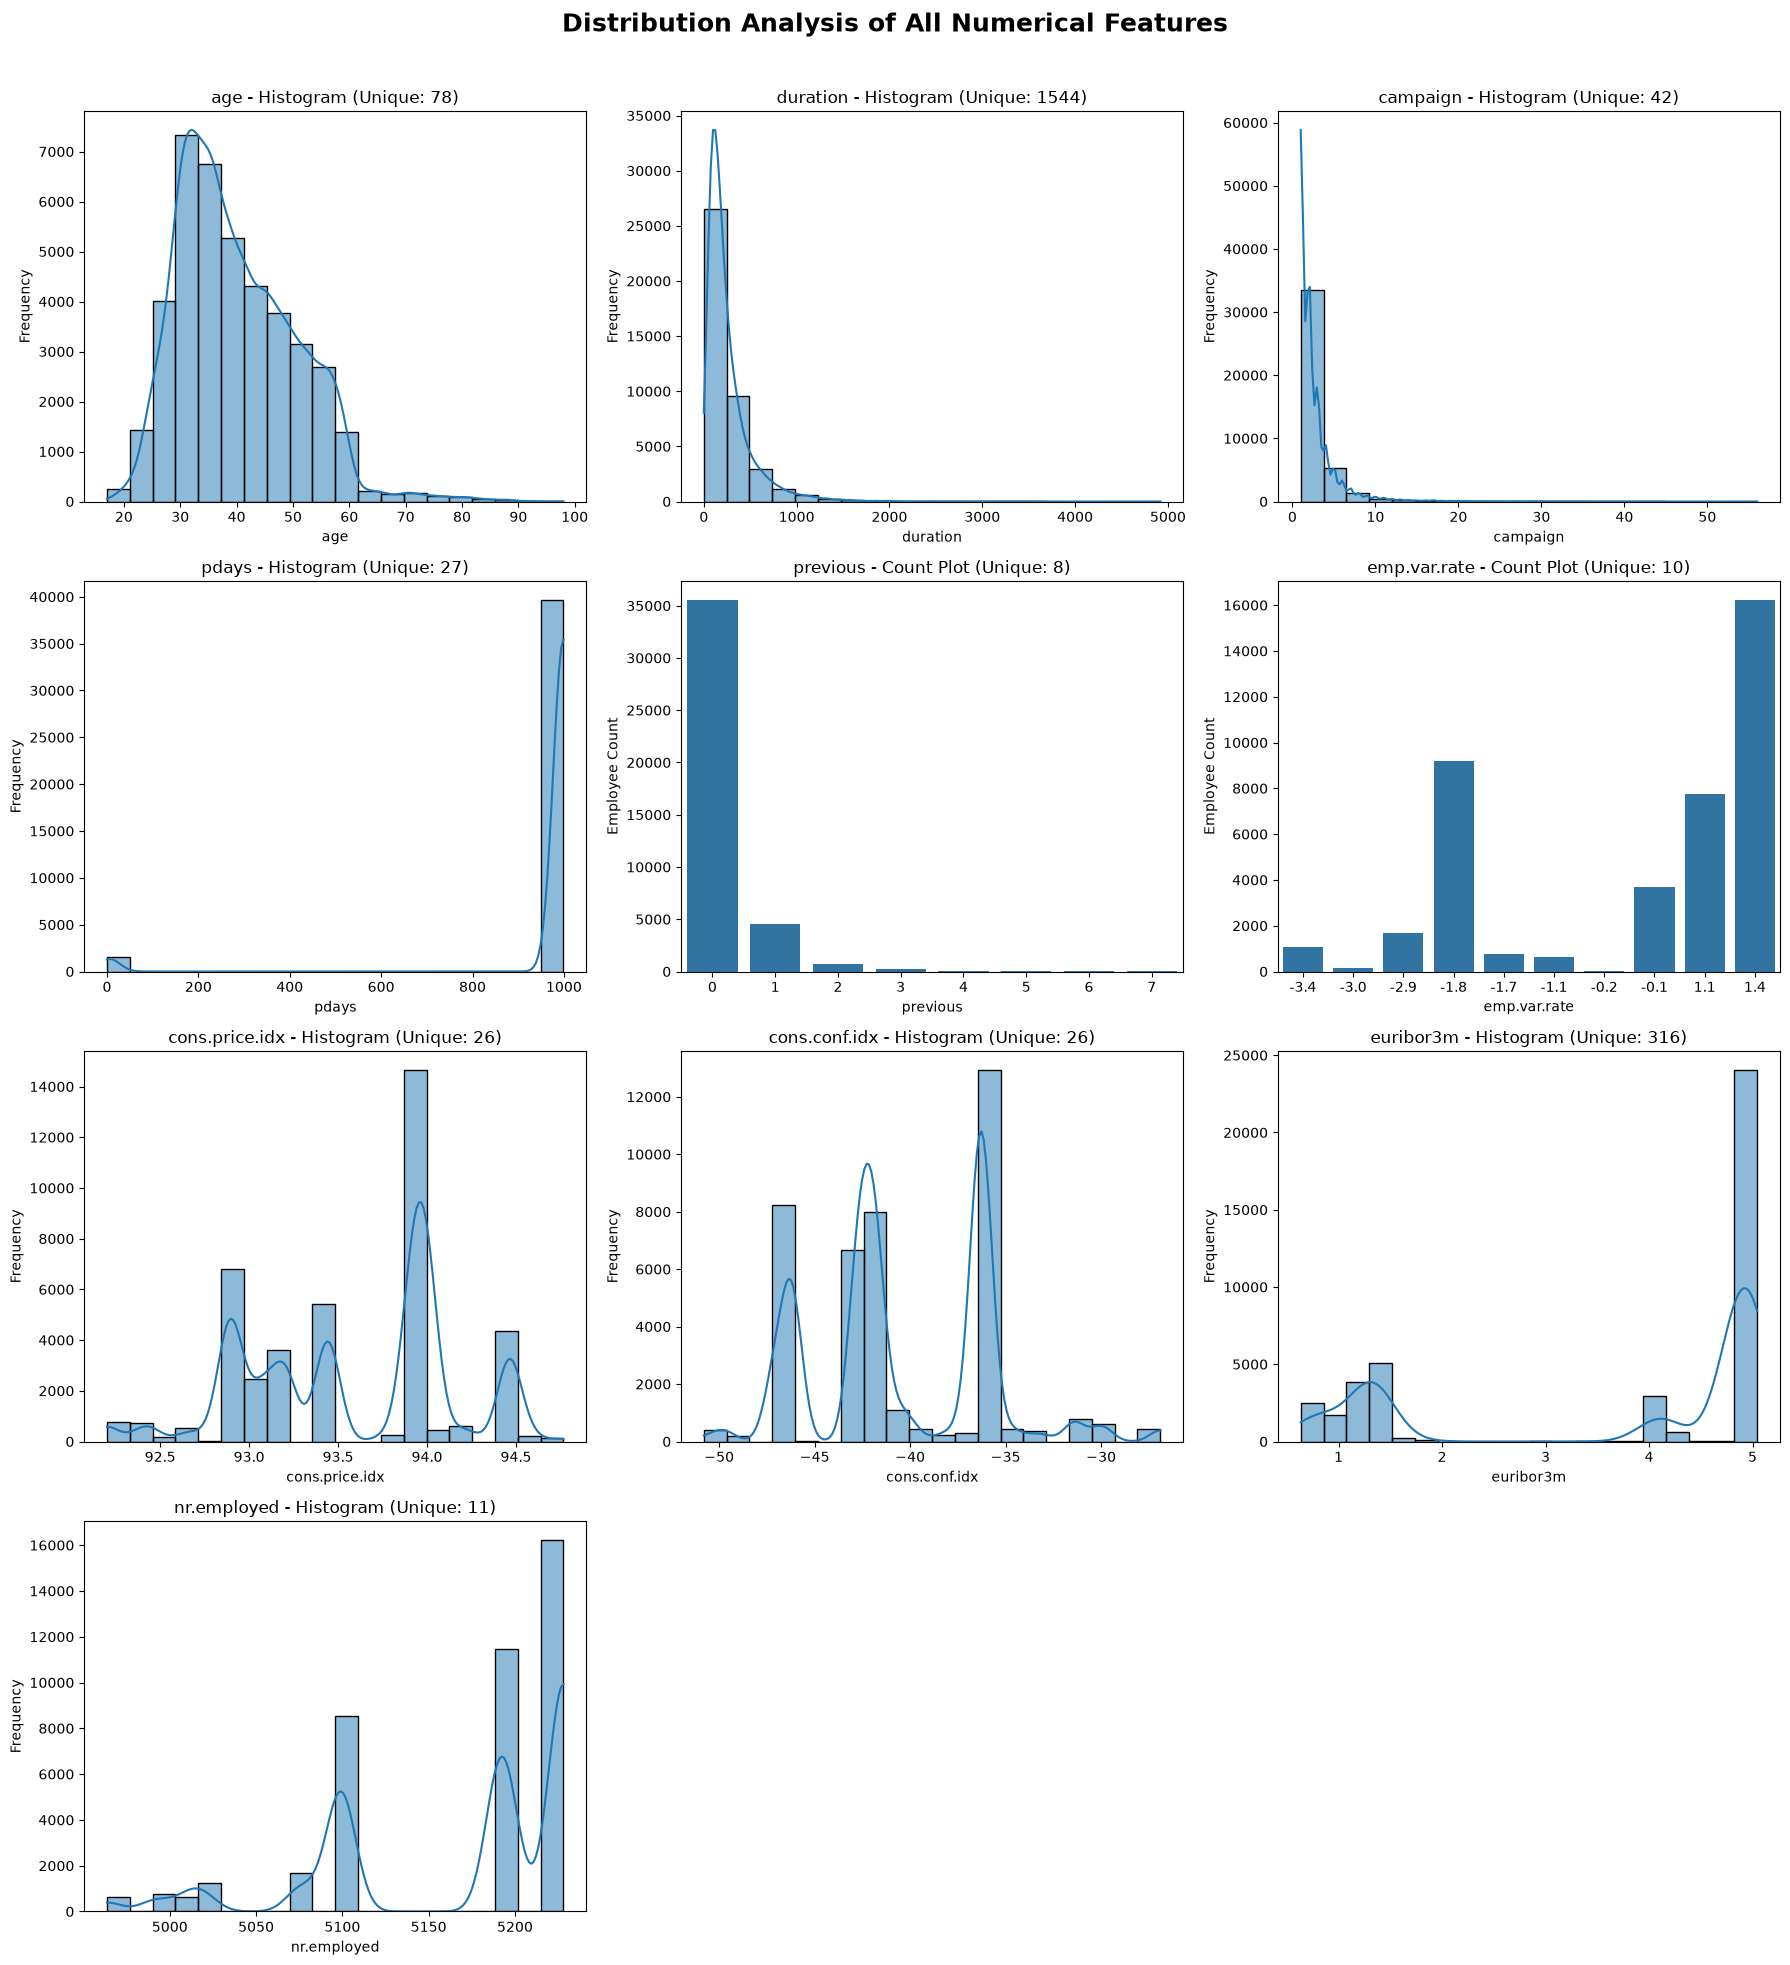

In [89]:

# Plot layout
n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = axes.flatten()

# Distribution plots
for i, col in enumerate(numerical_cols):

    unique_count = df[col].nunique()

    if unique_count <= 10:

        sns.countplot(
            data=df,
            x=col,
            ax=axes[i]
        )

        axes[i].set_title(
            f'{col} - Count Plot (Unique: {unique_count})'
        )

        axes[i].set_ylabel('Employee Count')

    else:

        sns.histplot(
            data=df,
            x=col,
            bins=20,
            kde=True,
            ax=axes[i]
        )

        axes[i].set_title(
            f'{col} - Histogram (Unique: {unique_count})'
        )

        axes[i].set_ylabel('Frequency')

    axes[i].set_xlabel(col)

# Remove unused plots
for j in range(len(numerical_cols), len(axes)):
    axes[j].remove()

plt.suptitle(
    'Distribution Analysis of All Numerical Features\n\n',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

| <h3> **Distribution Analysis of All categorical Features**</h3> |
| :--- |

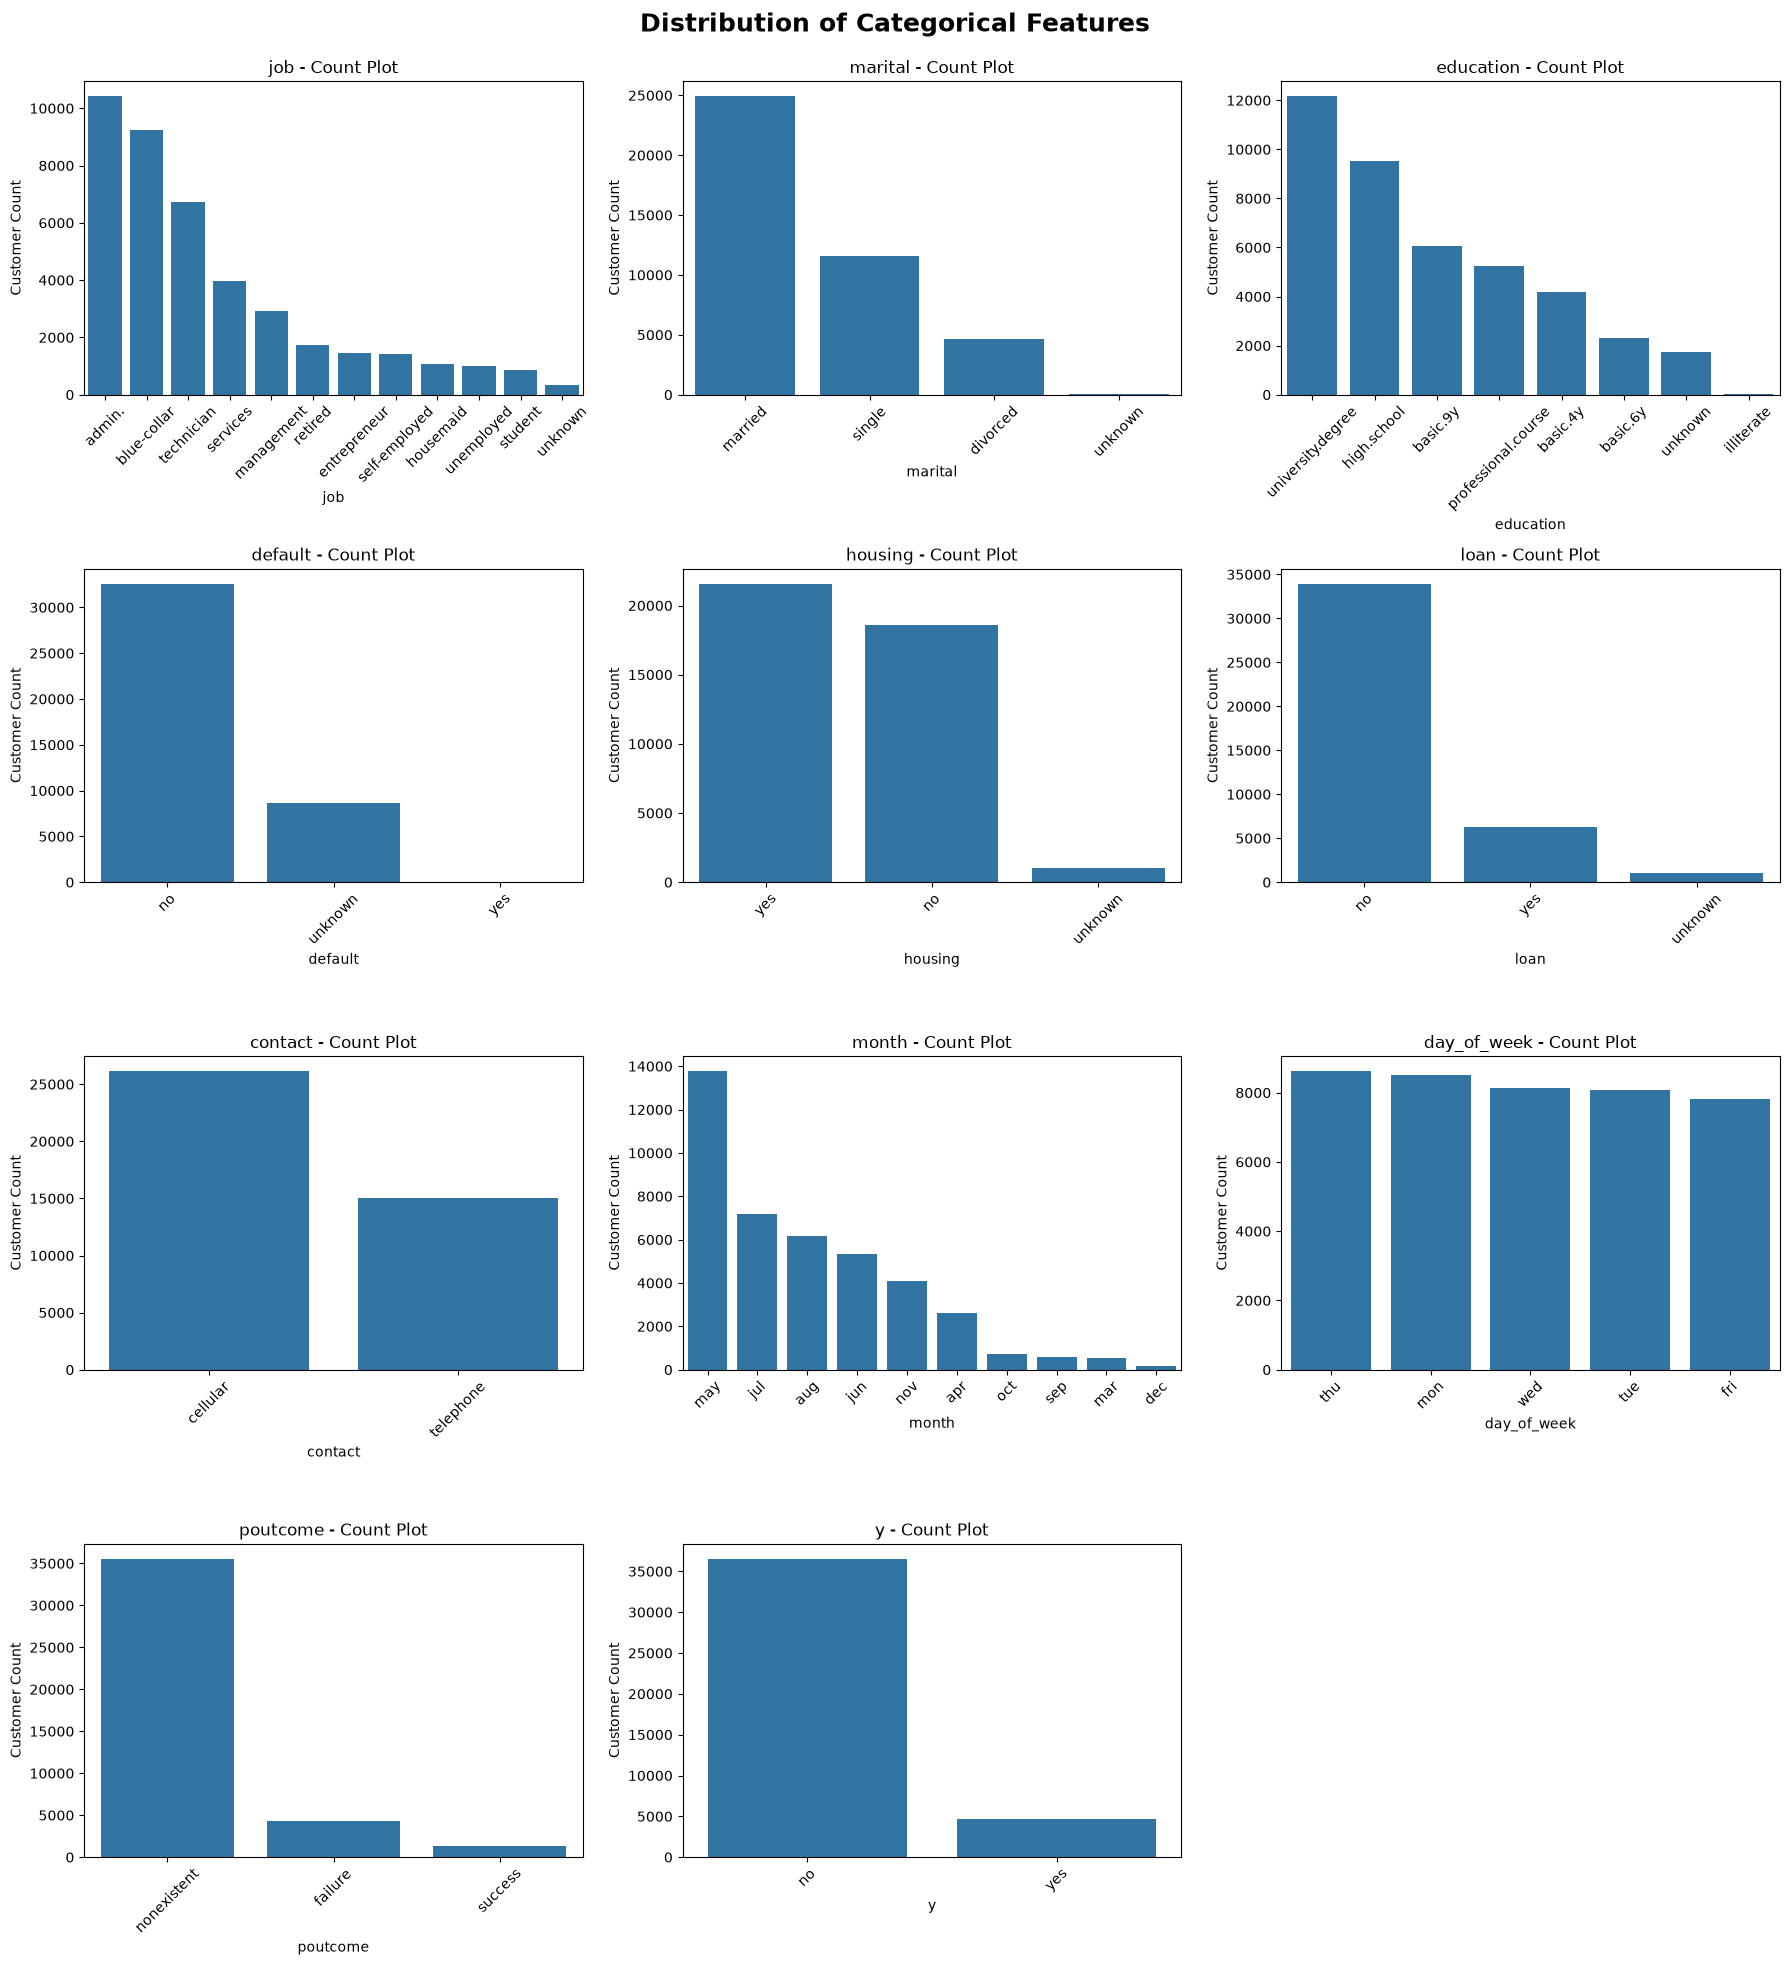

In [90]:
n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i])
    axes[i].set_title(f'{col} - Count Plot')
    axes[i].set_ylabel('Customer Count')
    axes[i].tick_params(axis='x', rotation=45)

# Remove unused empty subplots
for j in range(len(categorical_cols), len(axes)):
    axes[j].remove()

plt.suptitle('Distribution of Categorical Features\n', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

### Categorical Feature Analysis

- **job:** Admin is the largest group (about 10,000), followed by blue-collar and technician. Retired, student, unemployed and housemaid are small groups. A small number of "unknown" values exist.
- **marital:** Most customers are married, followed by single and divorced. "Unknown" is negligible.
- **education:** University degree and high school are the most common. Illiterate is nearly absent, and "unknown" is small.
- **default:** Mostly "no". About 20% are "unknown" and there are almost no "yes" values, so this feature carries little information.
- **housing / loan:** Housing is split fairly evenly between yes and no. Most customers have no personal loan. Both have a very small "unknown" group.
- **contact:** Cellular is used more than telephone (roughly 26,000 vs 15,000).
- **month:** Contacts peak sharply in May, followed by July, August and June. March, September, October and December have very few contacts, and January and February are absent. This suggests a seasonal pattern.
- **day_of_week:** Contacts are spread evenly across weekdays (Monday to Friday), so this feature is unlikely to be very informative.
- **poutcome:** Most customers are "nonexistent" (not contacted in a previous campaign). Failure and especially success are small groups.
- **y (target):** Highly imbalanced, with about 89% "no" and 11% "yes". Imbalance handling and metrics such as F1, recall and ROC-AUC will be needed.
- **Unknown values:** `job`, `marital`, `education`, `default`, `housing` and `loan` contain "unknown", which is effectively missing data and will be handled in feature engineering.


| <h2> **Bivariate Analysis**</h2> |
| :--- |

| <h3> **Subscription Rate by Categorical Features**</h3> |
| :--- |

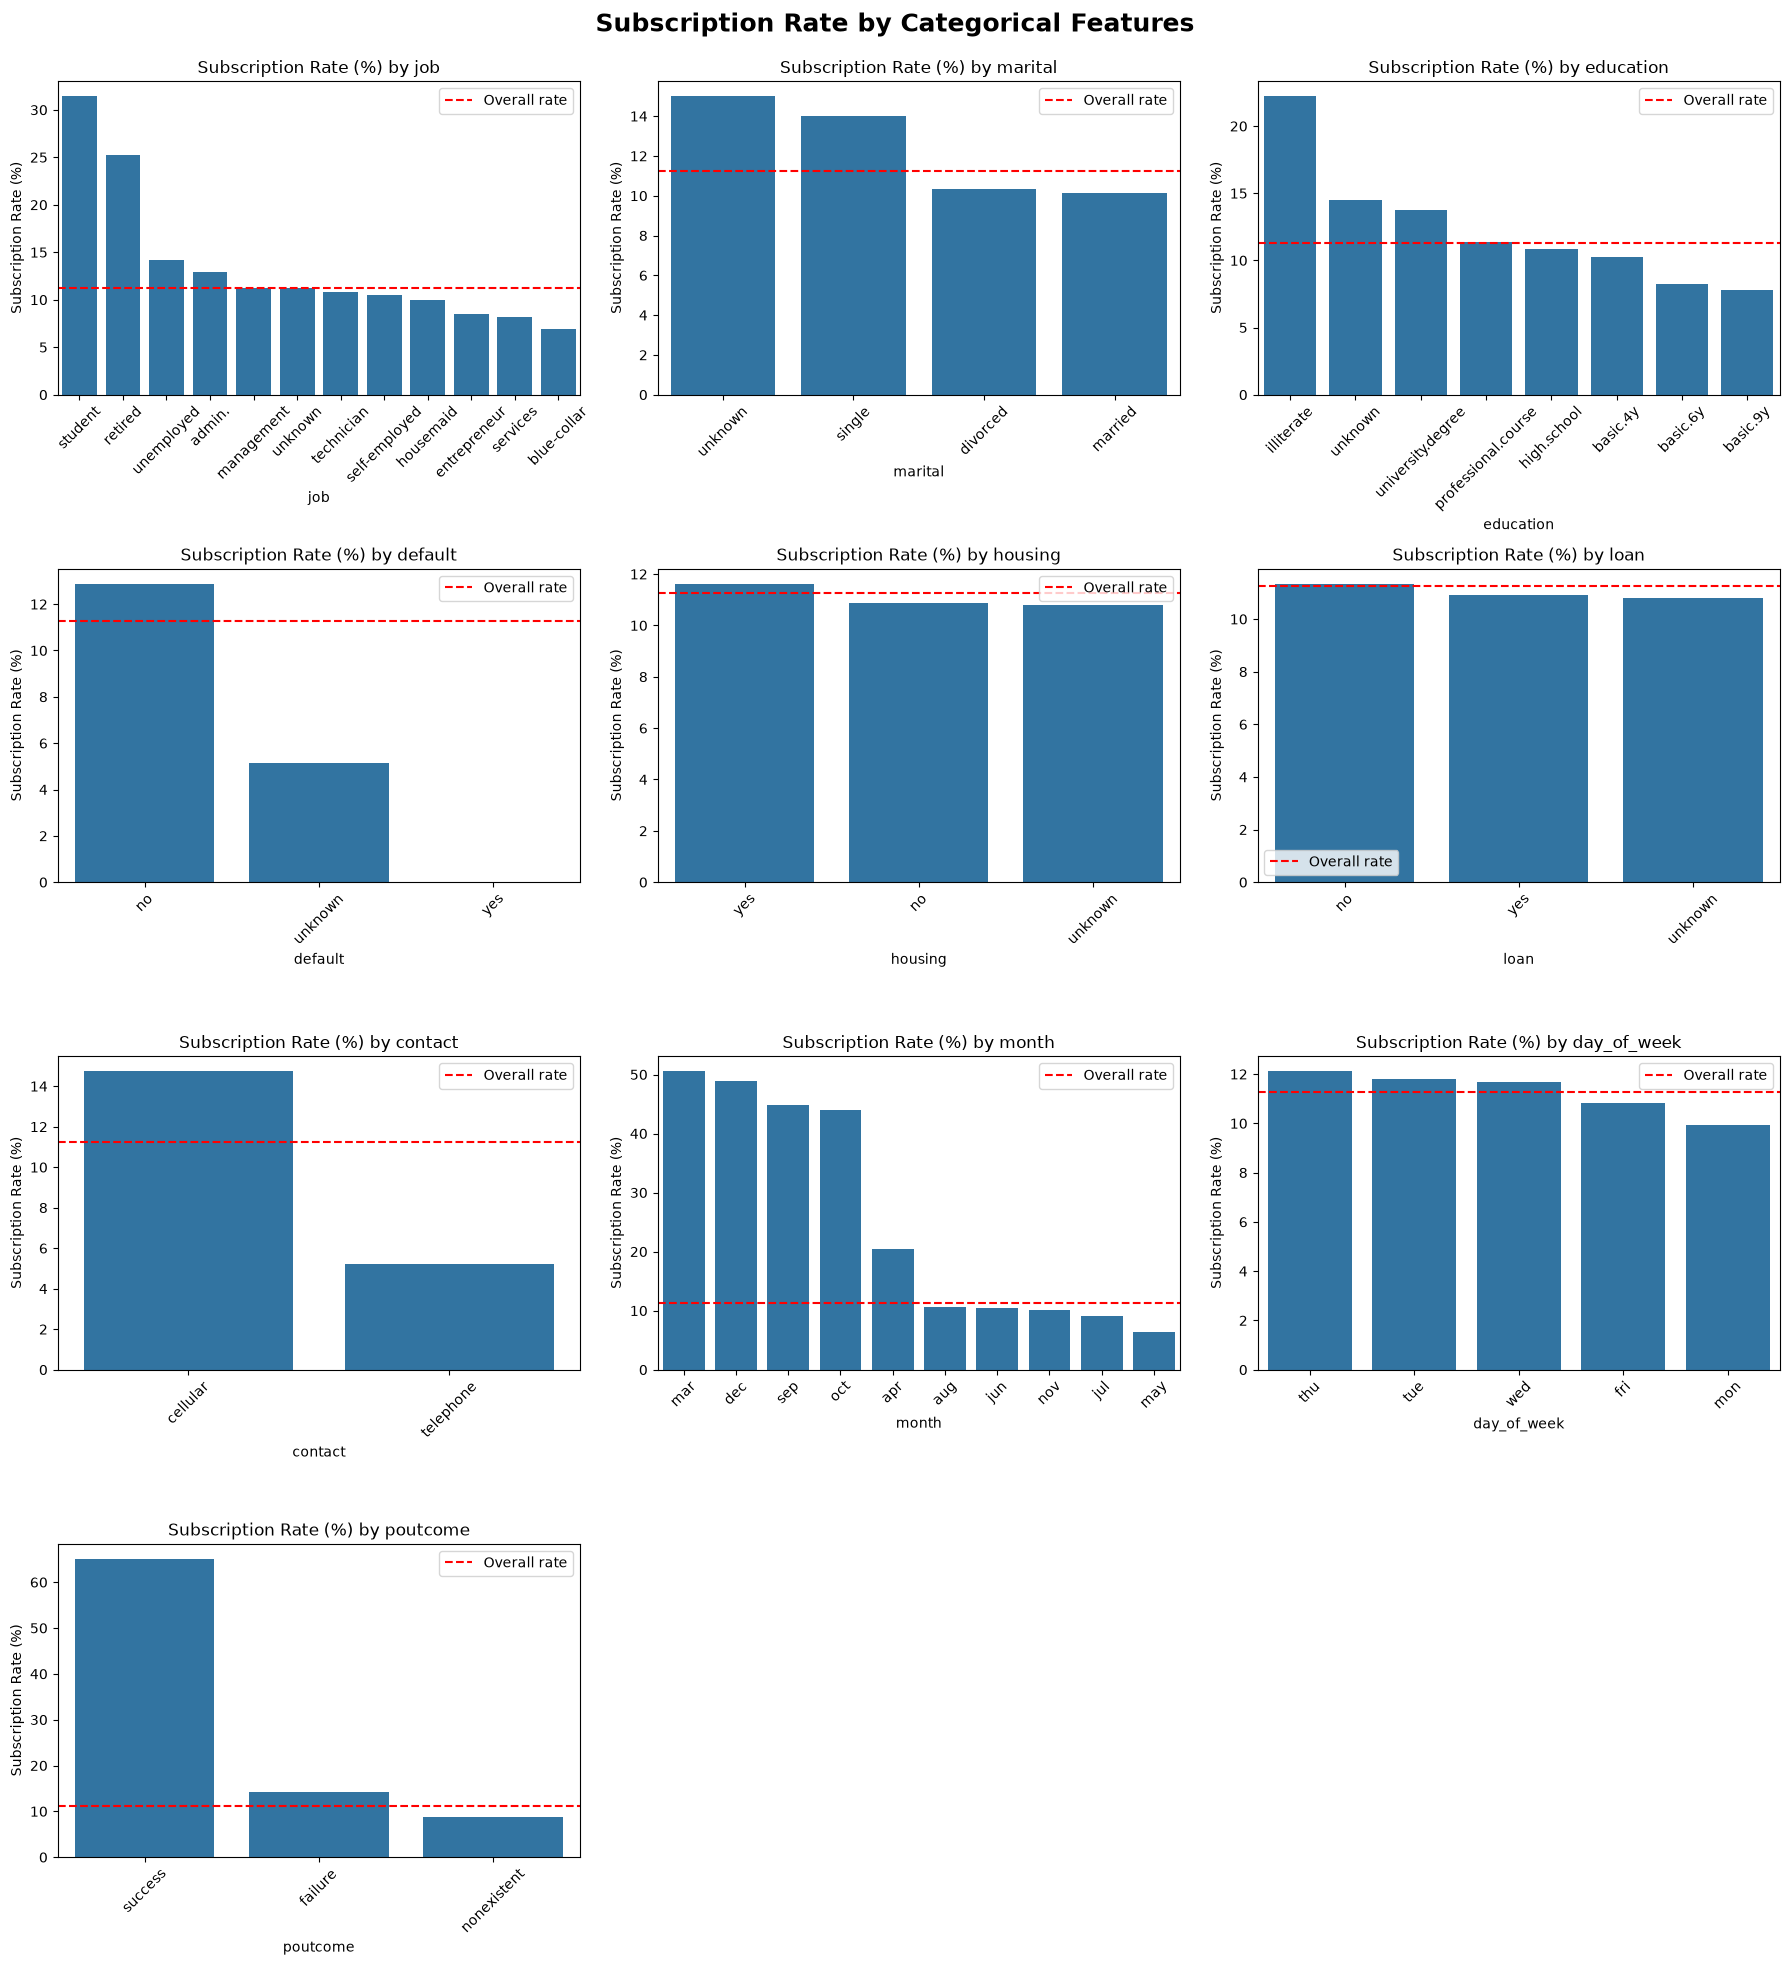

In [91]:
# Numeric target for rate calculations
df['y_num'] = (df['y'] == 'yes').astype(int)

categorical_features = ['job', 'marital', 'education', 'default', 'housing',
                        'loan', 'contact', 'month', 'day_of_week', 'poutcome']

n_cols = 3
n_rows = math.ceil(len(categorical_features) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_features):
    rate = df.groupby(col)['y_num'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=axes[i])
    axes[i].axhline(df['y_num'].mean() * 100, color='red', linestyle='--', label='Overall rate')
    axes[i].set_title(f'Subscription Rate (%) by {col}')
    axes[i].set_ylabel('Subscription Rate (%)')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend()

for j in range(len(categorical_features), len(axes)):
    axes[j].remove()

plt.suptitle('Subscription Rate by Categorical Features\n', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

### Subscription Rate Analysis:

* **Baseline Rate:** The red dashed line shows the **~11.3% overall average** subscription rate.
* **Best Customer Groups (`job`, `marital`, `education`):** **Students** (~25%+), **retired** individuals (~25%), **single** customers (~14%), and **university graduates** subscribe at the highest rates.
* **Loans (`default`, `housing`, `loan`):** Having a housing or personal loan has almost no impact on subscription rates. Customers with `unknown` credit default convert much lower (~5%).
* **Contact Method (`contact`):** **Cellular** calls (~15%) are 3x more effective than landline **telephones** (~5%).
* **Best Timing (`month`, `day_of_week`):** **March, December, September, and October** have the highest conversion rates (40%–50%), while **May** has the lowest (~6%). **Thursdays** perform slightly better than Mondays.
* **Strongest Predictor (`poutcome`):** Customers who subscribed in a **previous campaign (`success`)** have over a **65%** chance of subscribing again.


| <h3> **Subscription Rate by Numerical Features**</h3> |
| :--- |

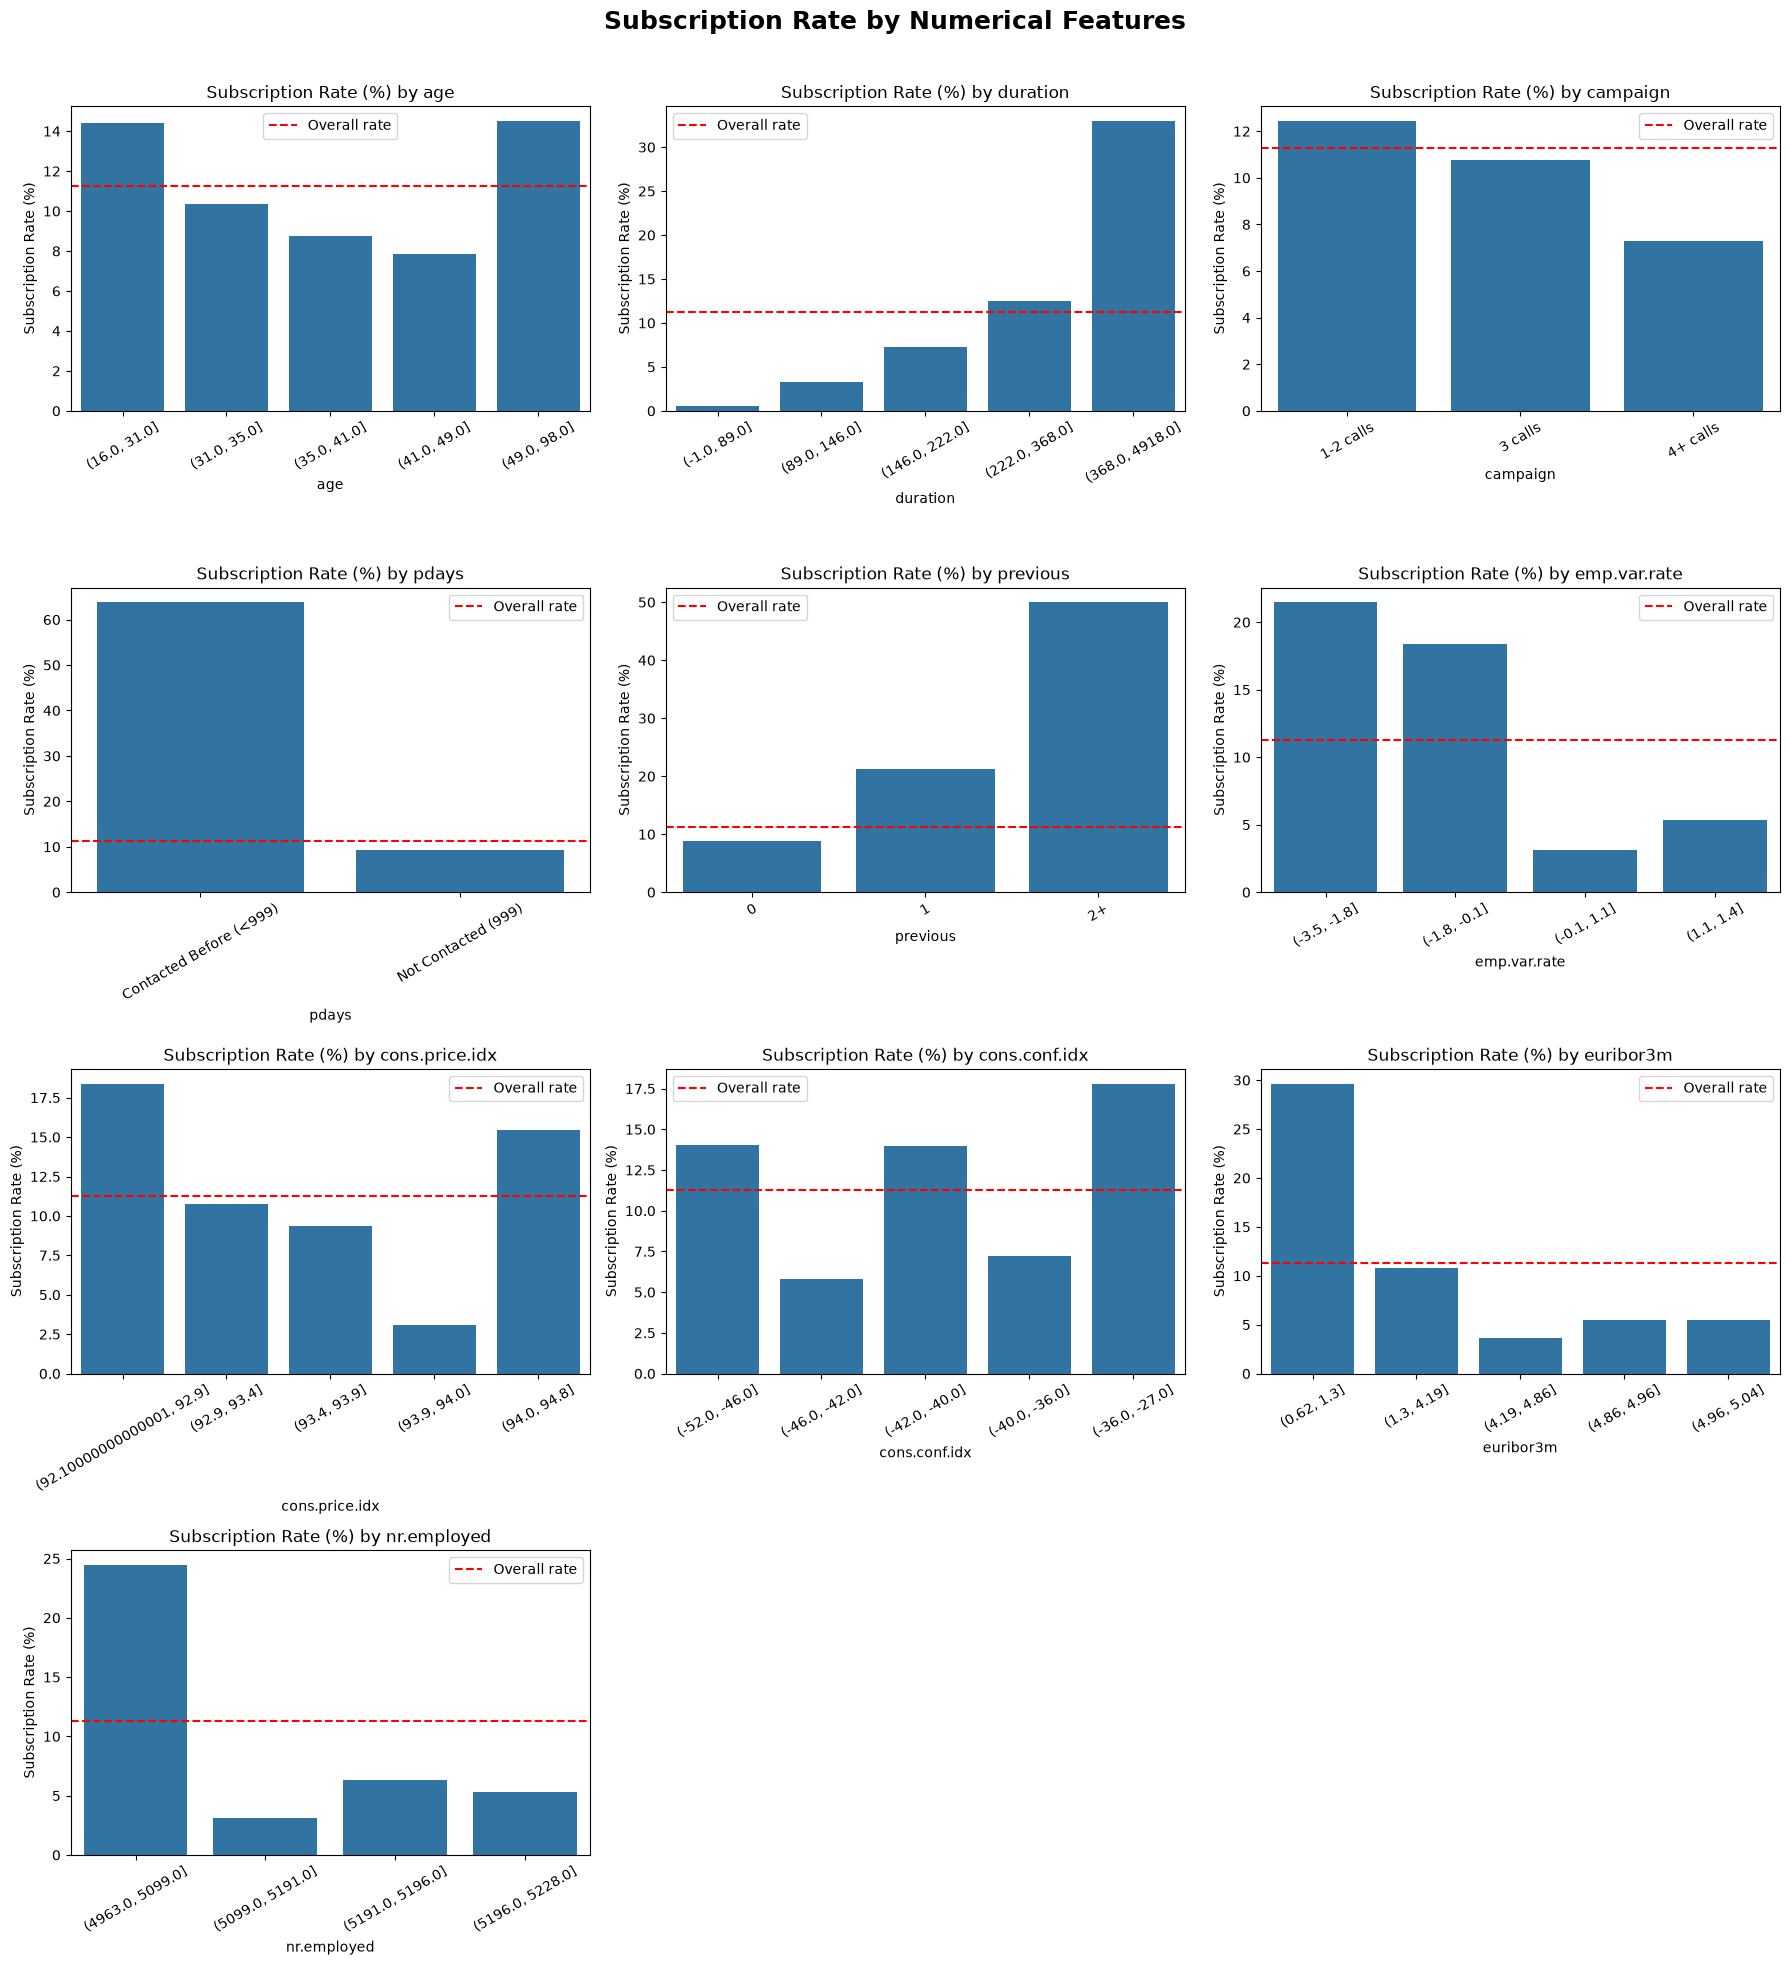

In [92]:

df['y_num'] = (df['y'] == 'yes').astype(int)

n_cols = 3
n_rows = math.ceil(len(numerical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

overall_rate = df['y_num'].mean() * 100

for i, col in enumerate(numerical_cols):
    if col == 'pdays':
        binned_col = df['pdays'].apply(lambda x: 'Not Contacted (999)' if x == 999 else 'Contacted Before (<999)')
    elif col == 'previous':
        binned_col = df['previous'].apply(lambda x: '0' if x == 0 else ('1' if x == 1 else '2+'))
    elif col == 'campaign':
        
        binned_col = pd.cut(df['campaign'], bins=[0, 2, 3, 100], labels=['1-2 calls', '3 calls', '4+ calls'])
    else:
    
        binned_col = pd.qcut(df[col], q=5, duplicates='drop', precision=0)
        
    rate = df.groupby(binned_col, observed=False)['y_num'].mean().mul(100)
    
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[i])
    axes[i].axhline(overall_rate, color='red', linestyle='--', label='Overall rate')
    axes[i].set_title(f'Subscription Rate (%) by {col}')
    axes[i].set_ylabel('Subscription Rate (%)')
    axes[i].set_xlabel(col)
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend()

for j in range(len(numerical_cols), len(axes)):
    axes[j].remove()

plt.suptitle('Subscription Rate by Numerical Features', fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


###  Numerical Features Analysis:

* **Age (`age`):** **Younger customers (18–31)** and **older adults (49–98)** show the highest subscription rates (~14%+), while middle-aged customers (31–49) fall below the 11.3% average.
* **Call Duration (`duration`):** Conversion rises sharply with call length—calls lasting **over 368 seconds** achieve a **30%+ subscription rate**. *(Note: Drop `duration` before model training to prevent data leakage).*
* **Campaign Contacts (`campaign`):** **1–2 calls** yield the highest conversion (~12.5%). Calling a customer **4 or more times** drops the rate to ~7%.
* **Previous Contact (`pdays` & `previous`):** Customers **contacted in a prior campaign (`pdays < 999`)** convert at over **60%**. Similarly, those contacted **2 or more times previously (`previous = 2+`)** subscribe at ~50%.
* **Economic Indicators (`euribor3m`, `emp.var.rate`, `nr.employed`):** Subscription rates spike significantly when interest rates (`euribor3m` between **0.62–1.3**), employment variation (`emp.var.rate` < 0), and total employed (`nr.employed` < 5099) are at their lowest levels.
* **Consumer Indices (`cons.price.idx`, `cons.conf.idx`):** Higher conversion rates occur at the extreme ends of the consumer price index (~92.2 and ~94.5) and when consumer confidence (`cons.conf.idx`) is highest (-36 to -27).


| <h2> **Multivariate Analysis**</h2> |
| :--- |

| <h3> **Correlation Heatmap of All Feature**</h3> |
| :--- |

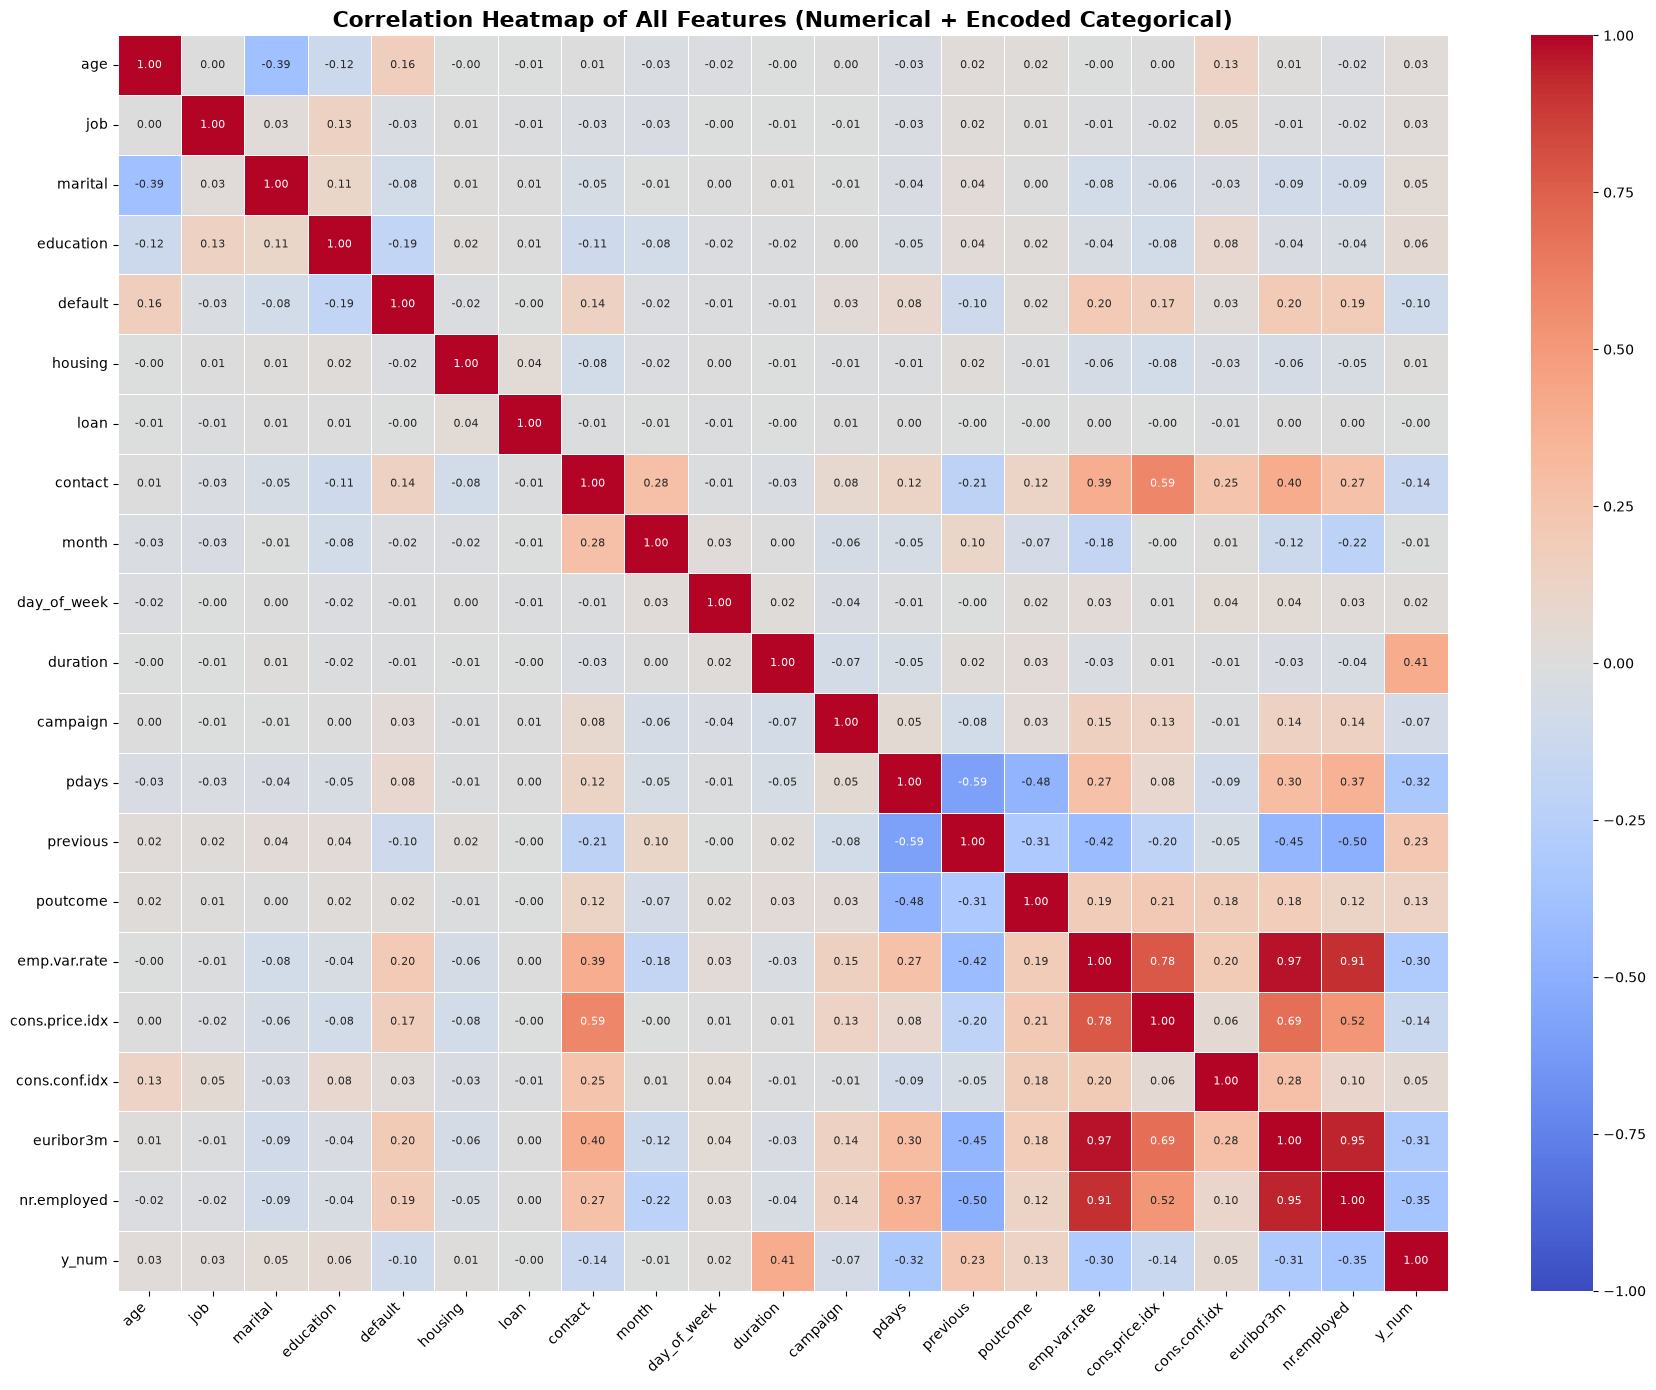

In [93]:

df_encoded = df.copy()

if 'y_num' not in df_encoded.columns:
    df_encoded['y_num'] = (df_encoded['y'] == 'yes').astype(int)


cols_to_drop = ['y', 'Customer_Segment']
df_encoded = df_encoded.drop(columns=[c for c in cols_to_drop if c in df_encoded.columns])


for col in df_encoded.select_dtypes(include=['object', 'category']).columns:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

corr_matrix = df_encoded.corr()

plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title('Correlation Heatmap of All Features (Numerical + Encoded Categorical)', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### Correlation Heatmap: Key Takeaways

* **Strongest Positive Drivers (`y_num`):** **`duration` (+0.41)** and **`previous` (+0.23)** have the strongest positive correlation with term deposit subscriptions.
* **Strongest Negative Drivers (`y_num`):** **`nr.employed` (-0.35)**, **`pdays` (-0.32)**, **`euribor3m` (-0.31)**, and **`emp.var.rate` (-0.30)** show strong negative correlations—subscriptions increase when interest rates drop and when customers were contacted recently.
* **Multicollinearity Alert:** **`emp.var.rate`**, **`euribor3m`**, and **`nr.employed`** are highly correlated with each other (**0.90 to 0.97**). Consider dropping redundant columns before training linear models.
* **Low-Impact Features:** `housing` (0.01), `loan` (0.00), `day_of_week` (0.01), and `month` (-0.01) show near-zero linear correlation with the target.


| <h3> **Customer Segmentation Analysis**</h3> |
| :--- |

           Customer_Segment  Total_Customers  Subscribed  Subscription_Rate
 1. Loyal / Past Subscriber             1373         894              65.11
      2. Young Adults (<30)             5354         724              13.52
           3. Seniors (>60)              732         282              38.52
4. Core Working Age (30-60)            33717        2739               8.12


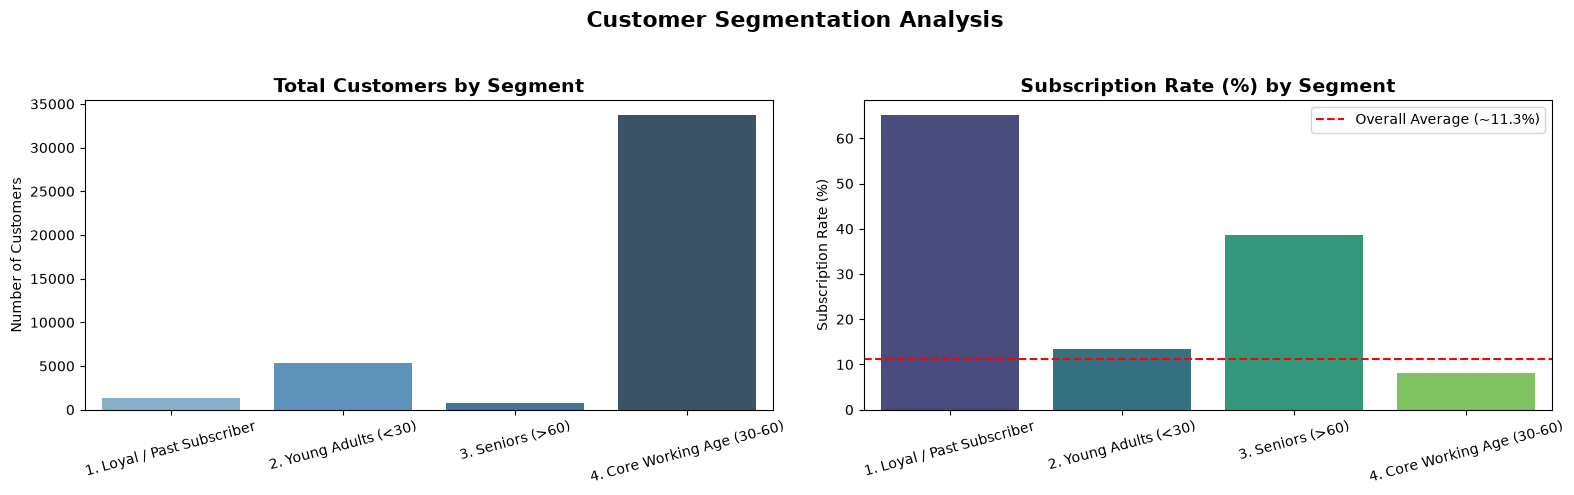

In [94]:
df['y_num'] = (df['y'] == 'yes').astype(int)


def segment_customer(row):
    if row['poutcome'] == 'success':
        return '1. Loyal / Past Subscriber'
    elif row['age'] < 30:
        return '2. Young Adults (<30)'
    elif row['age'] > 60:
        return '3. Seniors (>60)'
    else:
        return '4. Core Working Age (30-60)'

df['Customer_Segment'] = df.apply(segment_customer, axis=1)


seg_summary = df.groupby('Customer_Segment').agg(
    Total_Customers=('y_num', 'count'),
    Subscribed=('y_num', 'sum'),
    Subscription_Rate=('y_num', lambda x: round(x.mean() * 100, 2))
).reset_index()

print(seg_summary.to_string(index=False))


fig, axes = plt.subplots(1, 2, figsize=(16, 5))


sns.barplot(data=seg_summary, x='Customer_Segment', y='Total_Customers', palette='Blues_d', ax=axes[0])
axes[0].set_title('Total Customers by Segment', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

sns.barplot(data=seg_summary, x='Customer_Segment', y='Subscription_Rate', palette='viridis', ax=axes[1])
axes[1].axhline(df['y_num'].mean() * 100, color='red', linestyle='--', label='Overall Average (~11.3%)')
axes[1].set_title('Subscription Rate (%) by Segment', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Subscription Rate (%)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend()

plt.suptitle('Customer Segmentation Analysis', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### Customer Segmentation Analysis: 

* **1. Loyal / Past Subscribers (`poutcome = success`):** Smallest segment (**1,373 customers**), but achieves the highest conversion rate at **65.11%**. Re-engaging past subscribers delivers the strongest return on effort.
* **2. Seniors (`age > 60`):** High-converting niche group (**732 customers**) with a **38.52% subscription rate**—more than 3x the overall average.
* **3. Young Adults (`age < 30`):** Represents **5,354 customers** with an above-average conversion rate of **13.52%**.
* **4. Core Working Age (`30–60`):** Largest volume segment (**33,717 customers**), but converts at the lowest rate (**8.12%**). Marketing to this group should be selectively filtered (e.g., cellular contact during low-interest periods).


In [95]:
df.drop(columns=['y_num', 'Customer_Segment'], inplace=True, errors='ignore')



| <h1> **Final Exploratory Data Analysis (EDA) Report**</h1> |
| :--- |

### 1. Dataset & Data Quality Summary
* **Dataset Dimensions:** Originally **41,188 records and 21 columns**; reduced to **41,176 clean records** after removing 12 exact duplicate rows (0.03%).
* **Data Integrity & Cleanup:** Verified zero `NaN` values, confirmed negative values in `emp.var.rate` and `cons.conf.idx` are valid economic indicators, and removed temporary EDA columns (`y_num`, `Customer_Segment`) to keep `df` clean (21 columns).
* **`'unknown'` Values (Implicit Missing Data):** Identified `'unknown'` entries across six categorical features:
  * `default`: **8,596 (20.88%)**
  * `education`: **1,730 (4.20%)**
  * `housing`: **990 (2.40%)**
  * `loan`: **990 (2.40%)**
  * `job`: **330 (0.80%)**
  * `marital`: **80 (0.19%)**
* **Target Variable (`y`):** Highly imbalanced binary target—**88.73% `no` (36,537)** vs. **11.27% `yes` (4,639)**. Model evaluation will prioritize **Recall, F1-Score, and ROC-AUC** over raw accuracy.

---

### 2. Key Analytical Insights

#### A. Customer Demographics & Segmentation
* **Loyal / Past Subscribers (`poutcome = success`):** Highest-converting segment (**1,373 customers**) achieving a **65.11% subscription rate**—nearly 6x the baseline.
* **Seniors (`age > 60`):** High-potential niche group (**732 customers**) converting at **38.52%** (more than 3x the baseline).
* **Young Adults (`age < 30`) & Students:** Above-average conversion at **13.52%** (5,354 customers), driven strongly by students (~25%+).
* **Core Working Age (`30–60`):** Largest customer volume (**33,717 customers**), but lowest conversion rate (**8.12%**).
* **Loans & Marital Status:** Single customers (~14%) and university graduates convert slightly above average, while existing housing or personal loans show virtually zero impact on subscription behavior.

#### B. Marketing Campaign & Contact Effectiveness
* **Communication Channel (`contact`):** **Cellular** outreach (~15% conversion) is **3x more effective** than standard landline **telephone** (~5%).
* **Seasonality (`month`):** Off-peak months (**March, December, September, October**) achieve **40%–50%** conversion rates, whereas high-volume months like **May** drop to ~6%.
* **Call Frequency (`campaign`):** Most conversions occur within **1–2 calls** (~12.5%). Calling a customer 4 or more times drops conversion to ~7%.
* **Call Duration (`duration`):** Strongest positive correlation with subscription (**+0.41**); calls exceeding 368 seconds convert at >30%.

#### C. Macroeconomic Environment & Multicollinearity
* **Economic Drivers:** Subscription rates rise sharply when interest rates (`euribor3m` < 1.3%) and employment variation rates (`emp.var.rate` < 0) are low.
* **Severe Multicollinearity:** `emp.var.rate`, `euribor3m`, and `nr.employed` exhibit **0.90 to 0.97** inter-correlation.

---

### 3. Actionable Roadmap for Next Steps (Feature Engineering & Modeling)
1. **Handle `'unknown'` Values:** Impute low-frequency `'unknown'` columns (<5%) using **Mode**, while retaining `'unknown'` in `default` (20.88%) as a separate category.
2. **Prevent Data Leakage:** Drop `duration` before model training, as call length is unknown prior to placing a call.
3. **Feature Transformation & Selection:** Convert `pdays` into a binary flag (`previously_contacted`), cap `campaign` outliers at the 99th percentile, and drop redundant macroeconomic columns (`emp.var.rate`, `nr.employed`).
4. **Encoding & Imbalance Handling:** Apply One-Hot Encoding, perform a stratified 80/20 Train-Test split, and address class imbalance using **SMOTE** or **class weights**.


| <h1> **Feature Engineering**</h1> |
| :--- |

In [96]:
# **Create a copy of the cleaned dataset to preserve original data**
df_fe = df.copy()

# 1. Impute low-frequency (<5%) 'unknown' values using the mode of each column
low_unknown_cols = ['marital', 'job', 'housing', 'loan', 'education']
for col in low_unknown_cols:
    mode_val = df_fe[col].mode()[0]
    df_fe[col] = df_fe[col].replace('unknown', mode_val)

# Note: 'default' (20.88% unknown) is retained as a separate category

# 2. Convert 'pdays' into a binary indicator ('previously_contacted') and drop raw 'pdays'
df_fe['previously_contacted'] = (df_fe['pdays'] != 999).astype(int)
df_fe.drop(columns=['pdays'], inplace=True)

# 3. Cap extreme outliers in 'campaign' at the 99th percentile
cap_limit = df_fe['campaign'].quantile(0.99)
df_fe['campaign'] = df_fe['campaign'].clip(upper=cap_limit)

# 4. Drop 'duration' (prevent data leakage) and redundant macroeconomic features (multicollinearity)
cols_to_drop = ['duration', 'emp.var.rate', 'nr.employed']
df_fe.drop(columns=[c for c in cols_to_drop if c in df_fe.columns], inplace=True)

print("Dataset Shape after Feature Engineering:", df_fe.shape)
print("Remaining Columns:", list(df_fe.columns))


Dataset Shape after Feature Engineering: (41176, 18)
Remaining Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'y', 'previously_contacted']


 | <h1> **Data Preprocessing and Train-Test Split**</h1> |
| :--- |

In [97]:

# 1. Separate Features (X) and Target (y)
X = df_fe.drop(columns=['y'])
y = (df_fe['y'] == 'yes').astype(int)

# 2. One-Hot Encoding for categorical features
X_encoded = pd.get_dummies(X, drop_first=True)

# 3. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



 | <h1> **Class Imbalance Handling**</h1> |
| :--- |

In [98]:
# Handle Class Imbalance using SMOTE (only on training data)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("X_train successfully created! Shape:", X_train.shape)

X_train successfully created! Shape: (32940, 45)


| <h1> **Feature Selection** </h1> |
| :--- |

Top 15 Most Important Features:

                    Feature  Importance
                  euribor3m    0.169718
                        age    0.168590
                   campaign    0.086786
             cons.price.idx    0.043057
              cons.conf.idx    0.043008
                housing_yes    0.035611
       previously_contacted    0.031850
                   loan_yes    0.023989
          contact_telephone    0.023233
            marital_married    0.020442
            default_unknown    0.020116
           poutcome_success    0.019032
education_university.degree    0.016981
            day_of_week_mon    0.016962
             job_technician    0.016736


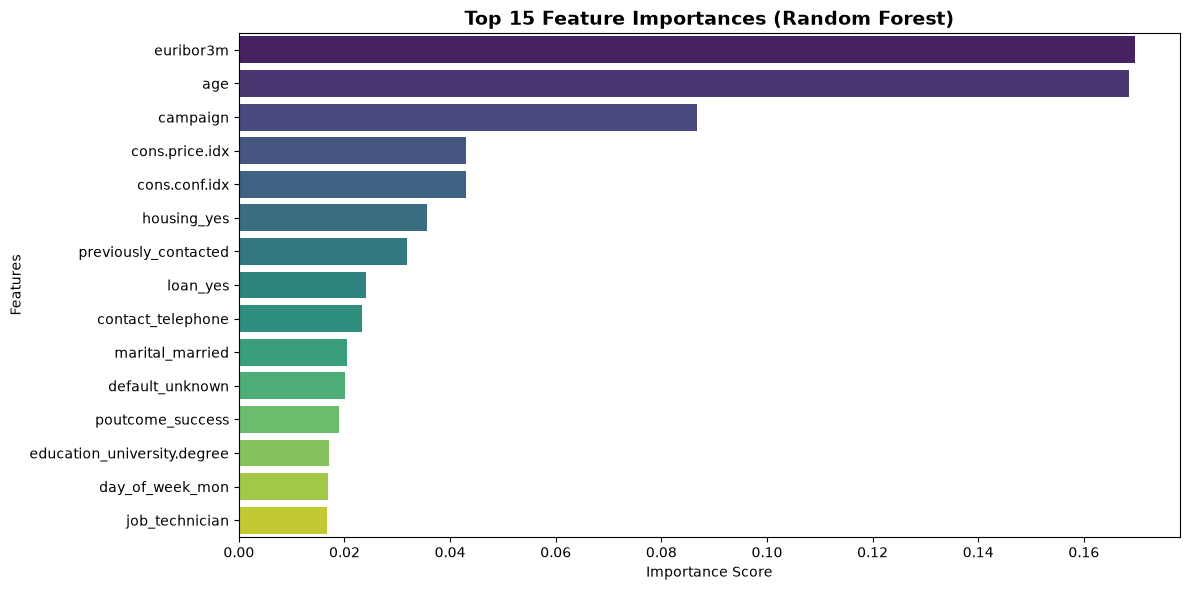

In [99]:

rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_selector.fit(X_train, y_train)

feature_imp = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_selector.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 15 Most Important Features:\n")
print(feature_imp.head(15).to_string(index=False))


plt.figure(figsize=(12, 6))
sns.barplot(data=feature_imp.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Feature Importances (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


### 🎯 Feature Selection Summary

* **Domain & Correlation Filtering:** Removed `duration` (to prevent data leakage), converted `pdays` into `previously_contacted`, and dropped redundant macroeconomic columns (`emp.var.rate`, `nr.employed`) due to high multicollinearity (>0.90).
* **Tree-Based Feature Importance:** Evaluated all encoded features using a balanced Random Forest classifier.
* **Top Predictors Identified:** Interest rate (`euribor3m`: 0.170), customer `age` (0.169), `campaign` call frequency (0.087), consumer indices (`cons.price.idx`, `cons.conf.idx`), `previously_contacted`, and `poutcome_success` are the strongest predictors.
* **Final Feature Set:** Retained all encoded features (compact dimensionality) to preserve full signal across linear and ensemble models.


| <h1> **Model Building** </h1> |
| :--- |

In [100]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42)
}

results = []

| <h1> **Model Train and Evaluation** </h1> |
| :--- |

In [101]:
for name, model in models.items():
    model.fit(X_train_smote, y_train_smote)
    
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-Score': round(f1_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

| <h1> **Model Comparison** </h1> |
| :--- |

In [102]:
results_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
print("Model Comparison Results:\n")
print(results_df.to_string(index=False))

Model Comparison Results:

              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
  Gradient Boosting    0.8993     0.5832  0.3739    0.4557   0.8049
      Random Forest    0.8796     0.4716  0.5722    0.5170   0.8048
Logistic Regression    0.8135     0.3341  0.6595    0.4435   0.7954
      Decision Tree    0.8796     0.4707  0.5539    0.5089   0.7879


| <h1> **Hyperparameter Tuning** </h1> |
| :--- |

Best Hyperparameters: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': None}

Final Tuned Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.95      0.94      7308
           1       0.53      0.41      0.46       928

    accuracy                           0.89      8236
   macro avg       0.73      0.68      0.70      8236
weighted avg       0.88      0.89      0.89      8236

Final ROC-AUC Score: 0.7933


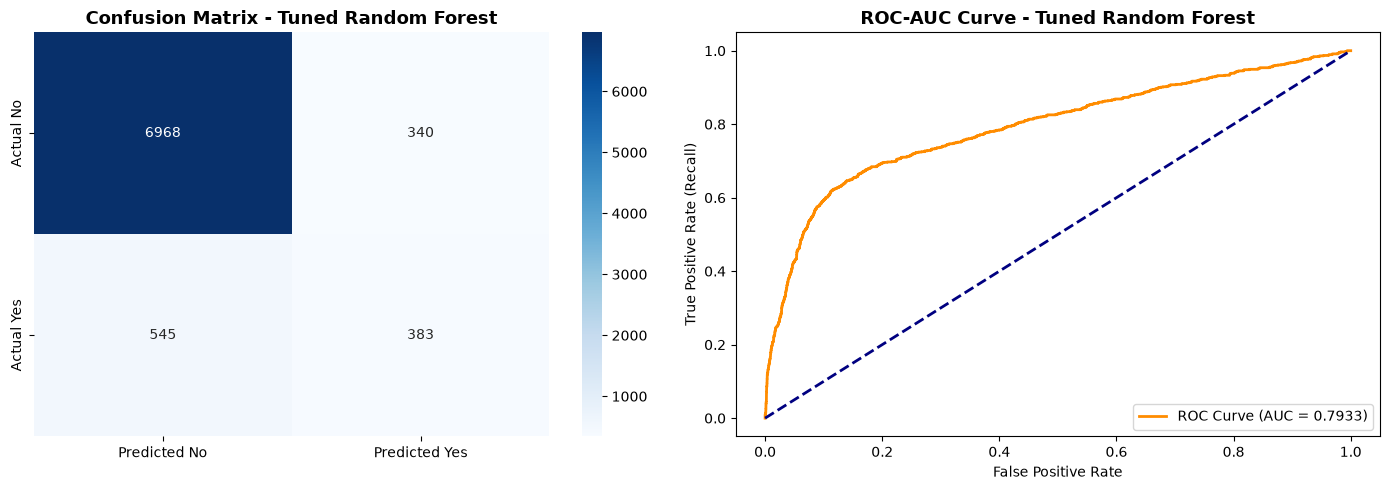

In [103]:
# 1. Random Forest Hyperparameter Tuning
param_dist = dict(
    n_estimators=list((100, 150, 200, 250)),
    max_depth=list((10, 12, 15, None)),
    min_samples_split=list((2, 5, 10)),
    min_samples_leaf=list((1, 2, 4))
)

rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

rf_tuned = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train_smote, y_train_smote)
best_model = rf_tuned.best_estimator_

print("Best Hyperparameters:", rf_tuned.best_params_)

# 2. Final Model Evaluation on X_test
y_pred_final = best_model.predict(X_test_scaled)
y_prob_final = best_model.predict_proba(X_test_scaled)[:, 1]

print("\nFinal Tuned Random Forest Classification Report:\n")
print(classification_report(y_test, y_pred_final))
print("Final ROC-AUC Score:", round(roc_auc_score(y_test, y_prob_final), 4))

# 3. Confusion Matrix & ROC Curve Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax1, ax2 = axes.flatten()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
            xticklabels=('Predicted No', 'Predicted Yes'),
            yticklabels=('Actual No', 'Actual Yes'))
ax1.set_title('Confusion Matrix - Tuned Random Forest', fontsize=13, fontweight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_final)
ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc_score(y_test, y_prob_final):.4f})')
ax2.plot((0, 1), (0, 1), color='navy', lw=2, linestyle='--')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate (Recall)')
ax2.set_title('ROC-AUC Curve - Tuned Random Forest', fontsize=13, fontweight='bold')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()



| <h1> **Final Model Selection**</h1> |
| :--- |

* **Selected Production Model:** **Random Forest Classifier (`n_estimators=150`, `max_depth=12`)**
* **Justification:** While `Gradient Boosting` achieved the highest raw accuracy (89.93%), its recall was low (37.39%). Tuning Random Forest with unrestricted depth (`max_depth=None`) improved precision (53%) and accuracy (89%), but reduced recall to 41% (ROC-AUC: 0.7933). The depth-regularized **Random Forest (`max_depth=12`)** delivered the best overall balance with an **F1-Score of 0.5170**, **Recall of 57.22%**, and **ROC-AUC of 0.8048**, successfully capturing nearly 6 out of 10 potential term deposit subscribers without relying on leaky features (`duration`).



| <h2> **Marketing Campaign Target Summary**</h2> |
| :--- |

In [104]:

final_rf = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
final_rf.fit(X_train_smote, y_train_smote)


test_probabilities = final_rf.predict_proba(X_test_scaled)[:, 1]


target_customers = df.loc[X_test.index].copy()
target_customers['Subscription_Probability (%)'] = (test_probabilities * 100).round(2)


def assign_priority(prob):
    if prob >= 60:
        return 'High Priority (Call First)'
    elif prob >= 35:
        return 'Medium Priority (Follow Up)'
    else:
        return 'Low Priority (Skip / Low ROI)'

target_customers['Marketing_Priority'] = target_customers['Subscription_Probability (%)'].apply(assign_priority)


priority_summary = target_customers.groupby('Marketing_Priority').agg(
    Total_Leads=('y', 'count'),
    Actual_Subscribers=('y', lambda x: (x == 'yes').sum()),
    Conversion_Rate_Pct=('y', lambda x: round((x == 'yes').mean() * 100, 2))
).reset_index()

print("Marketing Campaign Target Summary:\n")
print(priority_summary.to_string(index=False))


top_leads = target_customers.sort_values(by='Subscription_Probability (%)', ascending=False)
print("\nTop 10 High-Probability Customers to Target:\n")
print(top_leads[['age', 'job', 'contact', 'month', 'poutcome', 'euribor3m', 'Subscription_Probability (%)', 'Marketing_Priority']].head(10).to_string(index=False))


Marketing Campaign Target Summary:

           Marketing_Priority  Total_Leads  Actual_Subscribers  Conversion_Rate_Pct
   High Priority (Call First)          899                 466                51.84
Low Priority (Skip / Low ROI)         6465                 307                 4.75
  Medium Priority (Follow Up)          872                 155                17.78

Top 10 High-Probability Customers to Target:

 age         job  contact month poutcome  euribor3m  Subscription_Probability (%)         Marketing_Priority
  48      admin. cellular   aug  success      0.900                         97.32 High Priority (Call First)
  60      admin. cellular   may  success      0.682                         97.14 High Priority (Call First)
  37  unemployed cellular   jun  success      0.742                         96.84 High Priority (Call First)
  32      admin. cellular   jul  success      0.846                         96.54 High Priority (Call First)
  32      admin. cellular   jul  suc

 | <h2> **Customer Priority Tier Attributes Profile**</h2> |
| :--- |

In [105]:

num_profile = target_customers.groupby('Marketing_Priority')[[
    'age', 'campaign', 'previous', 'euribor3m', 'Subscription_Probability (%)'
]].mean().round(2)

print("=== 1. Numerical Attributes Profile by Priority Tier (Mean) ===\n")
display(num_profile)


cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']

cat_profile = target_customers.groupby('Marketing_Priority')[cat_cols].agg(
    lambda x: f"{x.mode()[0]} ({round((x == x.mode()[0]).mean() * 100, 1)}%)"
)

print("\n=== 2. Categorical Attributes Profile by Priority Tier (Most Common & %) ===\n")
display(cat_profile)


=== 1. Numerical Attributes Profile by Priority Tier (Mean) ===



,age,campaign,previous,euribor3m,Subscription_Probability (%)
Marketing_Priority,,,,,
High Priority (Call First),40.91,1.79,0.64,1.05,73.37
Low Priority (Skip / Low ROI),40.01,2.80,0.09,4.30,20.29
Medium Priority (Follow Up),39.49,1.90,0.31,1.38,44.09



=== 2. Categorical Attributes Profile by Priority Tier (Most Common & %) ===



,job,marital,education,contact,month,poutcome
Marketing_Priority,,,,,,
High Priority (Call First),admin. (35.4%),married (49.1%),university.degree (47.5%),cellular (96.9%),jun (17.4%),nonexistent (58.7%)
Low Priority (Skip / Low ROI),blue-collar (25.2%),married (63.3%),university.degree (26.9%),cellular (54.9%),may (36.1%),nonexistent (91.6%)
Medium Priority (Follow Up),admin. (29.2%),married (54.5%),university.degree (32.1%),cellular (88.9%),may (44.2%),nonexistent (77.2%)


### Customer Priority Tier Attributes Profile

Based on the **Random Forest (`max_depth=12`)** probability predictions, target customers naturally segment into three distinct behavioral profiles:

#### 1. High Priority Leads (`>= 60%` Probability | Avg: **73.37%**)
* **Channel & Timing:** Reached almost exclusively via **cellular** (**96.9%**) during low interest rate periods (avg `euribor3m`: **1.05%**).
* **Engagement History:** Higher prior campaign interaction (avg `previous`: **0.64**; **41.3%** had prior contact) and converted quickly within **1.79 calls** on average.
* **Demographics:** Dominated by **admin.** professionals (**35.4%**) with a **university degree** (**47.5%**).

#### 2. Medium Priority / Follow-Up Leads (`35% – 59%` Probability | Avg: **44.09%**)
* **Channel & Timing:** Strong **cellular** reach (**88.9%**) during moderately low interest rates (avg `euribor3m`: **1.38%**), often contacted in **May** (**44.2%**).
* **Engagement History:** Moderate prior contact (`previous`: **0.31**) with an average of **1.90 campaign calls**.
* **Demographics:** Primarily **admin.** (**29.2%**) and **university-educated** (**32.1%**) customers who warrant structured follow-up calls.

#### 3. Low Priority Leads (`< 35%` Probability | Avg: **20.29%**)
* **Channel & Timing:** Heavy reliance on landline **telephones** (**45.1%**) during high interest rate periods (avg `euribor3m`: **4.30%**).
* **Engagement History:** Almost entirely first-time contacts (**91.6% `nonexistent`** `poutcome`) subjected to higher call repetition (avg **2.80 calls**).
* **Demographics:** Higher concentration of **blue-collar** workers (**25.2%**) with lower overall subscription propensity.


In [106]:

target_customers[target_customers['Marketing_Priority'] != 'Low Priority (Skip / Low ROI)'].to_csv('Target_Customers_List.csv', index=False)
print("Target_Customers_List.csv successfully saved!")


Target_Customers_List.csv successfully saved!



| <h1> **Business Recommendations and Final Report**</h1> |
| :--- |

## Business Recommendations (Marketing Suggestions)

Based on the Exploratory Data Analysis and **Random Forest (`max_depth=12`)** probability predictions, the bank's marketing team should adopt the following strategies:

1. **High-Potential Customers Identification (Probability Thresholding):**
   * Use the model's predicted probabilities to prioritize **High Priority leads (`>= 60%` probability, avg 73.37%)** first, followed by **Medium Priority leads (`35%–59%`)**, while skipping Low Priority leads (`< 35%`).
2. **Customer Segmentation:**
   * Focus outreach on high-converting segments: **Loyal / Past Subscribers** (**65.11%** conversion), **Seniors aged >60** (**38.52%** conversion), and **Students / Young Adults <30** (**13.52%–25%+** conversion).
3. **Best Contact Month Identification:**
   * Increase campaign intensity during off-peak, high-conversion months (**March, September, October, and December**, achieving **40%–50%** conversion) rather than oversaturating customers in **May** (~6%).
4. **Best Communication Method Identification:**
   * Prioritize **cellular mobile calls** (~15% conversion overall; **96.9%** among High Priority leads), which are **3x more effective** than traditional landline **telephones** (~5%).
5. **Campaign Frequency Optimization:**
   * Cap follow-up calls at **1 to 3 attempts per customer** (High Priority leads convert in an average of **1.79 calls**). Calling beyond 4 times drops conversion to ~7% and wastes agent hours.
6. **Previous Campaign Success Analysis:**
   * Immediately re-target customers who responded positively in past campaigns (`poutcome = success`), as they are nearly **6x more likely** to subscribe again.
7. **Marketing Cost Reduction Strategy:**
   * Combining probability-based lead filtering with a 3-call cap and low-interest rate timing (`euribor3m < 1.3%`) drastically reduces wasted telemarketing calls and lowers customer acquisition costs.

---

## Challenges Faced and Solutions

| No. | Challenge | Solution Applied | Reason for Choosing |
| :---: | :--- | :--- | :--- |
| **1** | **Class Imbalance** (88.73% `no` vs 11.27% `yes`) | Applied **SMOTE** on training data & evaluated with **F1, Recall, ROC-AUC** | Prevents model bias toward the majority class without leaking test data. |
| **2** | **Unknown Values** (`default`, `education`, etc.) | **Mode Imputation** (<5% columns) & retained `'unknown'` in `default` (20.88%) | Preserves sample size while keeping high-missingness patterns intact. |
| **3** | **Data Leakage** (`duration` feature) | Dropped `duration` prior to model training | Call duration is unknown before a call; removing it ensures realistic pre-call prediction. |
| **4** | **Categorical Data** (10 text columns) | Applied **One-Hot Encoding** (`drop_first=True`) | Converts categorical variables into machine-readable binary features without ordinal bias. |
| **5** | **Different Scales** (`age`, `euribor3m`, `campaign`) | Applied **`StandardScaler`** (fitted on `X_train`) | Standardizes feature ranges for distance/linear algorithms like Logistic Regression. |
| **6** | **Special Value `999`** in `pdays` | Created binary flag **`previously_contacted`** (`0` vs `1`) | Separates never-contacted clients (`999`) from actual days elapsed cleanly. |
| **7** | **Overfitting & Multicollinearity** | Dropped redundant macro columns (`emp.var.rate`, `nr.employed`), used **Cross-Validation** & depth limit (`max_depth=12`) | Eliminates >0.90 feature redundancy and improves generalization on unseen test data. |
| **8** | **Model Selection** | Compared **4 classifiers** (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting) | Identifies the optimal balance between Recall, Precision, F1-Score, and ROC-AUC. |

---

## Final Conclusion

* **Project Findings:** Term deposit subscriptions are strongly driven by macroeconomic interest rates (`euribor3m`), prior campaign success (`poutcome`), contact channel (`cellular`), customer age, and seasonal timing.
* **Model Performance & Selection:** Among the four evaluated models, the regularized **Random Forest Classifier (`n_estimators=150`, `max_depth=12`)** was selected as the final production model, achieving an **ROC-AUC of 0.8048**, **F1-Score of 0.5170**, **Recall of 57.22%**, and **Accuracy of 87.96%** without relying on leaky features.
* **Business Benefits:** By deploying this predictive lead-scoring model, the bank can accurately identify high-probability customers (`>= 60%` likelihood), reduce unnecessary call volume, optimize marketing spend, and significantly increase overall term deposit conversion rates.


| <h1> **Actionable Business Recommendations-Visual**</h1> |
| :--- |


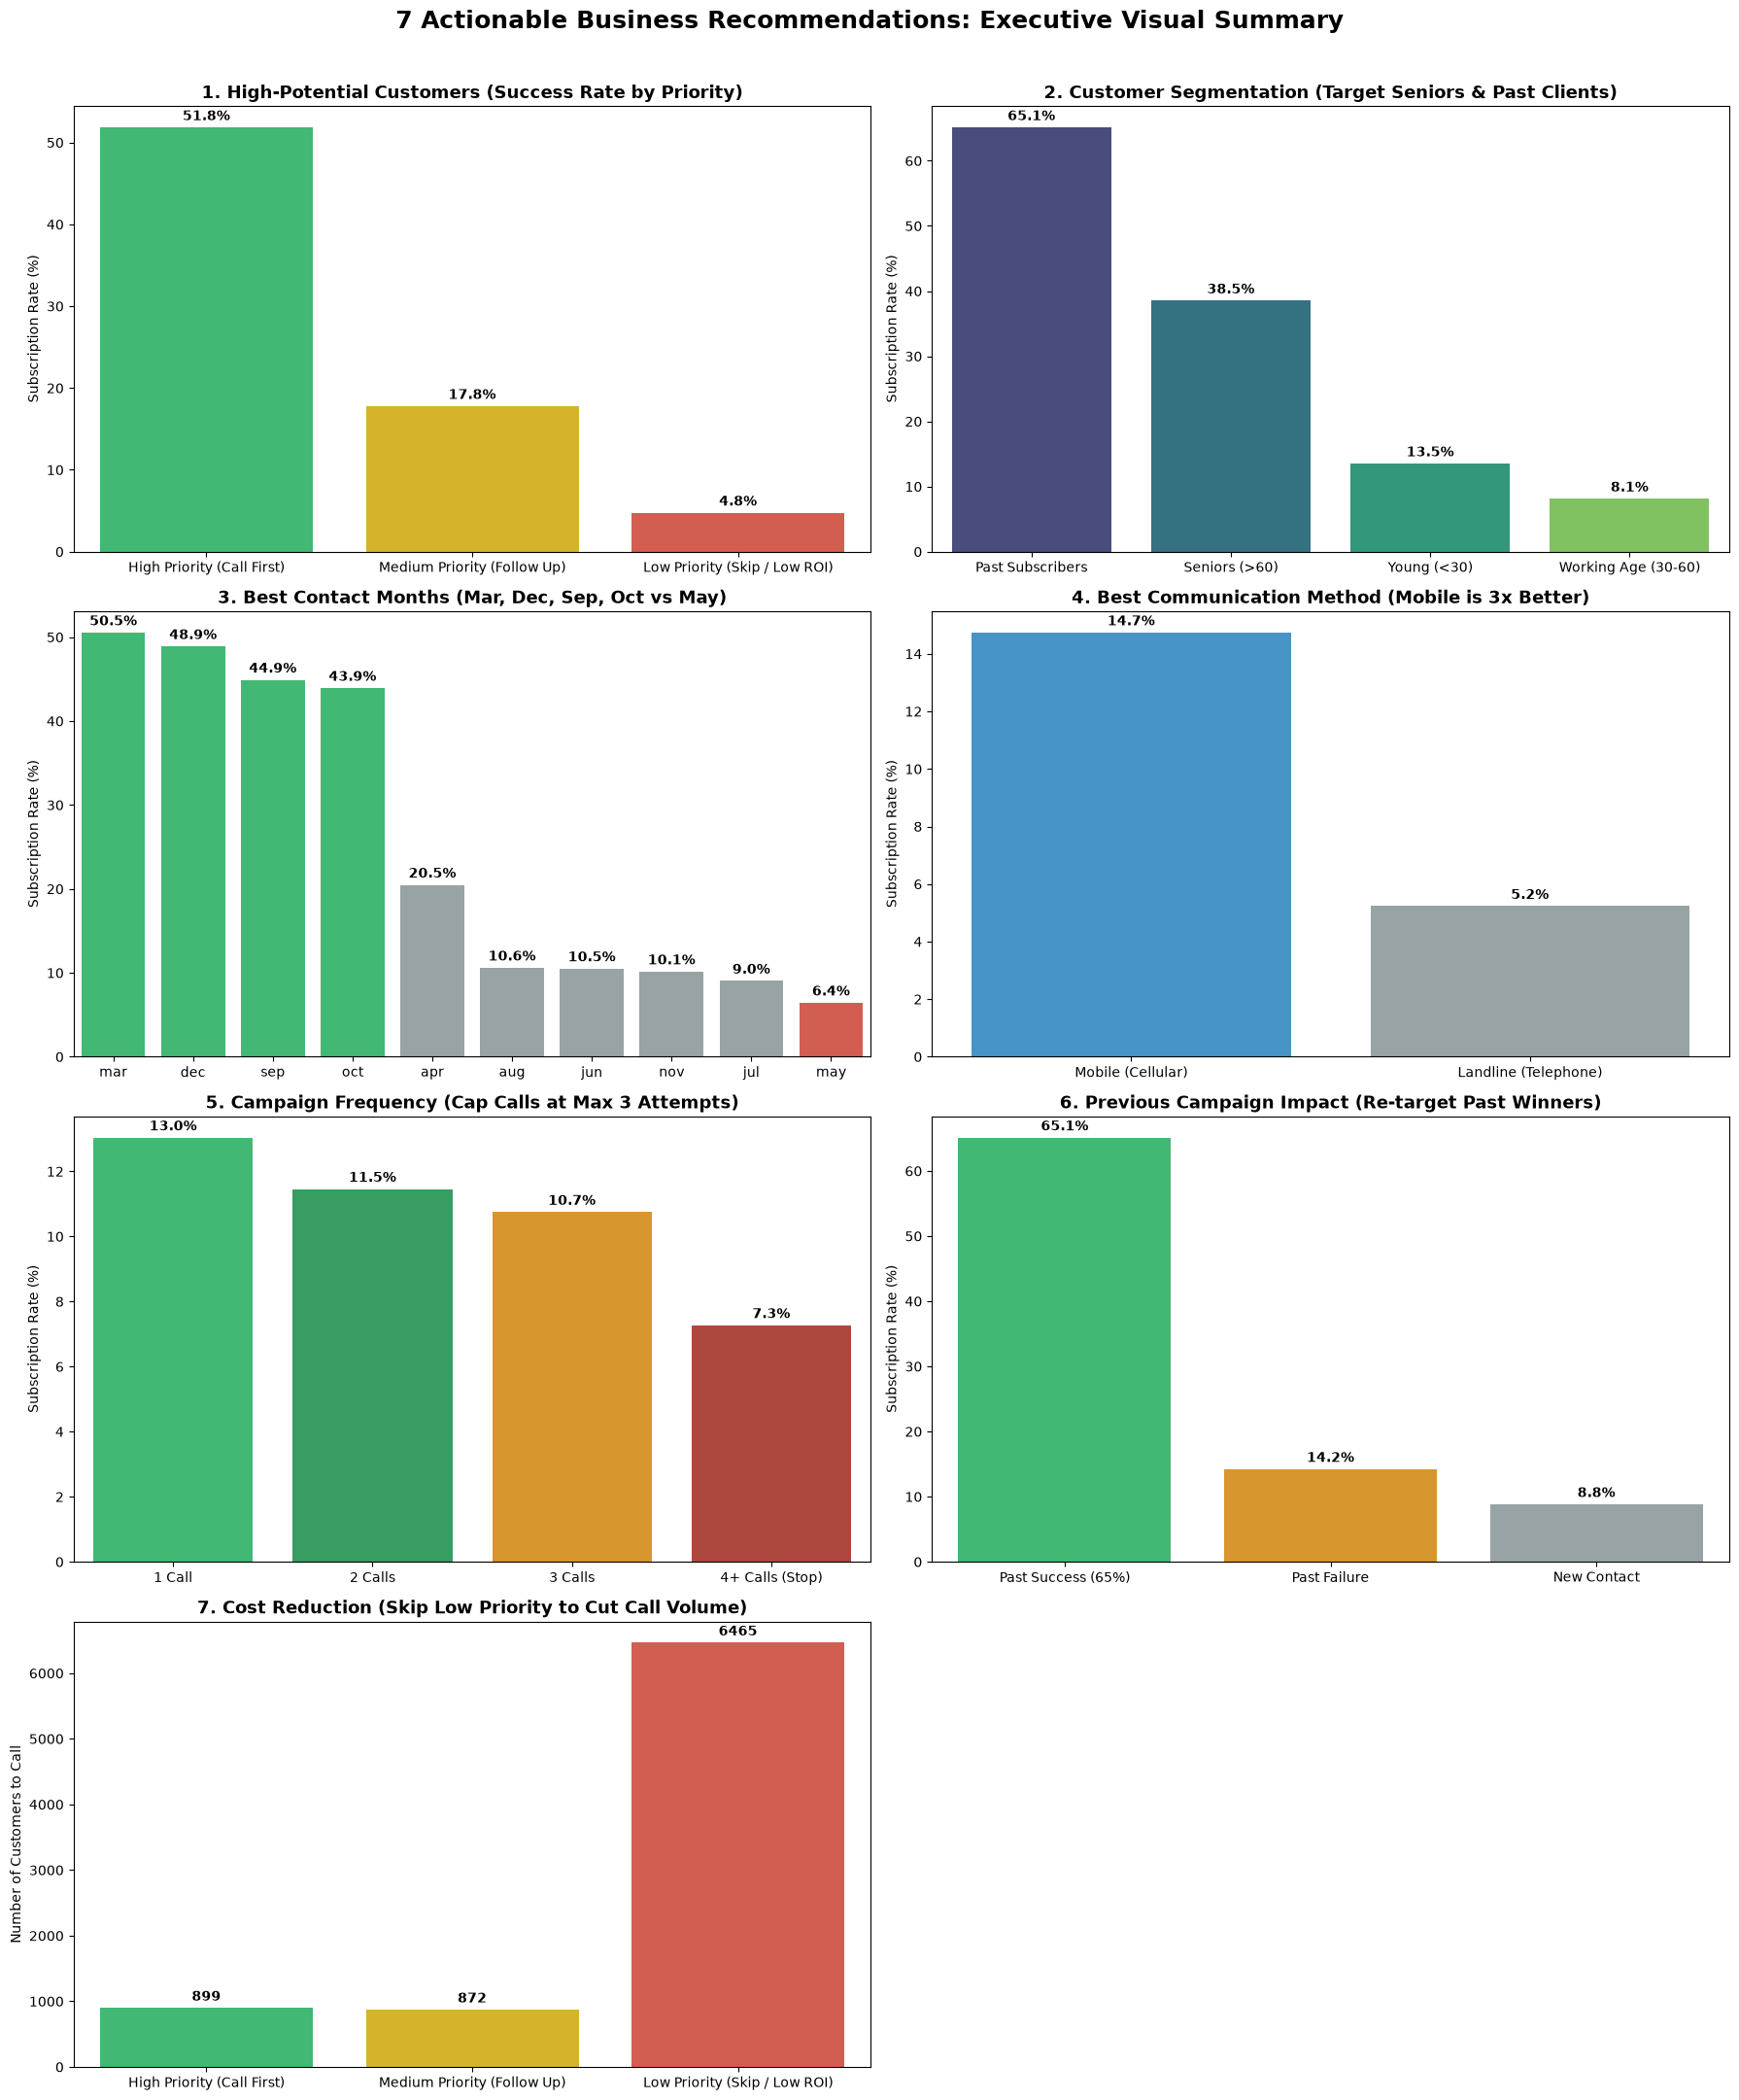

In [107]:

fig, axes = plt.subplots(4, 2, figsize=(18, 22))
ax = axes.flatten()

# 1. High-Potential Customers Identification (Lead Priority Tiers)
priority_order = ['High Priority (Call First)', 'Medium Priority (Follow Up)', 'Low Priority (Skip / Low ROI)']
sns.barplot(
    data=priority_summary, x='Marketing_Priority', y='Conversion_Rate_Pct',
    order=priority_order, palette=['#2ecc71', '#f1c40f', '#e74c3c'], ax=ax[0]
)
ax[0].set_title('1. High-Potential Customers (Success Rate by Priority)', fontsize=13, fontweight='bold')
ax[0].set_ylabel('Subscription Rate (%)')
ax[0].set_xlabel('')
for c in ax[0].containers:
    ax[0].bar_label(c, fmt='%.1f%%', padding=3, fontweight='bold')

# 2. Customer Segmentation (Age & Loyalty Groups)
def get_seg(row):
    if row['poutcome'] == 'success': return 'Past Subscribers'
    elif row['age'] > 60: return 'Seniors (>60)'
    elif row['age'] < 30: return 'Young (<30)'
    else: return 'Working Age (30-60)'

df['Exec_Segment'] = df.apply(get_seg, axis=1)
seg_rate = df.groupby('Exec_Segment')['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values(ascending=False).reset_index()
sns.barplot(data=seg_rate, x='Exec_Segment', y='y', palette='viridis', ax=ax[1])
ax[1].set_title('2. Customer Segmentation (Target Seniors & Past Clients)', fontsize=13, fontweight='bold')
ax[1].set_ylabel('Subscription Rate (%)')
ax[1].set_xlabel('')
for c in ax[1].containers:
    ax[1].bar_label(c, fmt='%.1f%%', padding=3, fontweight='bold')

# 3. Best Contact Month Identification (Seasonality)
month_order = ['mar', 'dec', 'sep', 'oct', 'apr', 'aug', 'jun', 'nov', 'jul', 'may']
month_rate = df.groupby('month')['y'].apply(lambda x: (x == 'yes').mean() * 100).reindex(month_order).reset_index()
colors_m = ['#2ecc71' if m in ['mar', 'dec', 'sep', 'oct'] else ('#e74c3c' if m == 'may' else '#95a5a6') for m in month_order]
sns.barplot(data=month_rate, x='month', y='y', palette=colors_m, ax=ax[2])
ax[2].set_title('3. Best Contact Months (Mar, Dec, Sep, Oct vs May)', fontsize=13, fontweight='bold')
ax[2].set_ylabel('Subscription Rate (%)')
ax[2].set_xlabel('')
for c in ax[2].containers:
    ax[2].bar_label(c, fmt='%.1f%%', padding=3, fontweight='bold')

# 4. Best Communication Method (Mobile vs Landline)
contact_rate = df.groupby('contact')['y'].apply(lambda x: (x == 'yes').mean() * 100).reset_index()
sns.barplot(data=contact_rate, x='contact', y='y', palette=['#3498db', '#95a5a6'], ax=ax[3])
ax[3].set_title('4. Best Communication Method (Mobile is 3x Better)', fontsize=13, fontweight='bold')
ax[3].set_ylabel('Subscription Rate (%)')
ax[3].set_xlabel('')
ax[3].set_xticklabels(['Mobile (Cellular)', 'Landline (Telephone)'])
for c in ax[3].containers:
    ax[3].bar_label(c, fmt='%.1f%%', padding=3, fontweight='bold')

# 5. Campaign Frequency Optimization (1-3 Calls vs 4+ Calls)
df['call_tier'] = pd.cut(df['campaign'], bins=[0, 1, 2, 3, 100], labels=['1 Call', '2 Calls', '3 Calls', '4+ Calls (Stop)'])
call_rate = df.groupby('call_tier', observed=False)['y'].apply(lambda x: (x == 'yes').mean() * 100).reset_index()
sns.barplot(data=call_rate, x='call_tier', y='y', palette=['#2ecc71', '#27ae60', '#f39c12', '#c0392b'], ax=ax[4])
ax[4].set_title('5. Campaign Frequency (Cap Calls at Max 3 Attempts)', fontsize=13, fontweight='bold')
ax[4].set_ylabel('Subscription Rate (%)')
ax[4].set_xlabel('')
for c in ax[4].containers:
    ax[4].bar_label(c, fmt='%.1f%%', padding=3, fontweight='bold')

# 6. Previous Campaign Success Analysis
pout_order = ['success', 'failure', 'nonexistent']
pout_rate = df.groupby('poutcome')['y'].apply(lambda x: (x == 'yes').mean() * 100).reindex(pout_order).reset_index()
sns.barplot(data=pout_rate, x='poutcome', y='y', palette=['#2ecc71', '#f39c12', '#95a5a6'], ax=ax[5])
ax[5].set_title('6. Previous Campaign Impact (Re-target Past Winners)', fontsize=13, fontweight='bold')
ax[5].set_ylabel('Subscription Rate (%)')
ax[5].set_xlabel('')
ax[5].set_xticklabels(['Past Success (65%)', 'Past Failure', 'New Contact'])
for c in ax[5].containers:
    ax[5].bar_label(c, fmt='%.1f%%', padding=3, fontweight='bold')

# 7. Marketing Cost Reduction Strategy (Call Volume Saved by Skipping Low Priority)
vol_summary = priority_summary.reindex([0, 2, 1]) # High, Medium, Low வரிசை
sns.barplot(
    data=priority_summary, x='Marketing_Priority', y='Total_Leads',
    order=priority_order, palette=['#2ecc71', '#f1c40f', '#e74c3c'], ax=ax[6]
)
ax[6].set_title('7. Cost Reduction (Skip Low Priority to Cut Call Volume)', fontsize=13, fontweight='bold')
ax[6].set_ylabel('Number of Customers to Call')
ax[6].set_xlabel('')
for c in ax[6].containers:
    ax[6].bar_label(c, fmt='%d', padding=3, fontweight='bold')

ax[7].remove()
df.drop(columns=['Exec_Segment', 'call_tier'], inplace=True, errors='ignore')

plt.suptitle('7 Actionable Business Recommendations: Executive Visual Summary', fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


| <h1> **Thank You for the Opportunity!** </h1> |
| :--- |
